## 📋 Important Setup Notes

### Kaggle Scores File

This notebook expects a `kaggle_scores.csv` file in the **root directory** with the following format:

```csv
model_name,source,score
exp_1_tfidf_log,experiments,0.99123
exp_1_tfidf_log,experiments_old,0.98987
exp_2_tfidf_ridge,experiments,0.99234
...
```

**Columns:**
- `model_name`: Experiment name (e.g., `exp_1_tfidf_log`, `exp_2_tfidf_ridge_optuna`)
- `source`: Either `experiments` (deduplicated) or `experiments_old` (original data)
- `score`: Kaggle public leaderboard ROC-AUC score

**Alternative:** If `kaggle_scores.csv` doesn't exist, the notebook will fall back to:
- `experiments/kaggle_results.csv` (for deduplicated models)
- `experiments_old/kaggle_results.csv` (for original data models)

---

### Directory Structure

```
├── experiments/              # Models trained on deduplicated data
│   ├── exp_1_tfidf_log/
│   │   ├── metrics.json
│   │   └── exp_1_tfidf_log_submission.csv
│   ├── exp_2_tfidf_ridge/
│   └── ...
├── experiments_old/          # Models trained on original data
│   ├── exp_1_tfidf_log/
│   │   ├── metrics.json
│   │   └── exp_1_tfidf_log_submission.csv
│   └── ...
├── kaggle_scores.csv        # (Optional but recommended)
└── Evaluation.ipynb         # This notebook
```

---

# 📊 Model Evaluation & Analysis Report

## Table of Contents

1. **Setup and Data Loading**
   - Import libraries and load experiment metrics
   - Load Kaggle submission scores
   - Merge CV and Kaggle metrics

2. **Cross-Validation Performance Analysis**
   - Summary table of CV metrics
   - ROC-AUC visualization with confidence intervals
   - Fold-level variance analysis

3. **Kaggle Leaderboard Performance**
   - Public leaderboard rankings (30% of test set)
   - Performance visualization by model family
   
4. **Generalization Analysis**
   - CV vs Kaggle scatter plot
   - Generalization gap analysis
   - Correlation analysis

5. **Model Architecture Comparison**
   - Performance by model family
   - Optuna optimization impact
   
6. **Statistical Testing**
   - Paired t-tests for top models
   - Significance analysis

7. **Final Recommendations**
   - Composite ranking system
   - Top model candidates
   
8. **Key Findings & Strategic Recommendations**
   - Performance overview
   - Risk assessment
   - Submission strategy

9. **Export Results**
   - Generate CSV files for documentation

---

# Comprehensive Model Evaluation Report

**Competition:** Kaggle Competition 2  
**Dataset:** ~5000 training samples, ~1300 test samples  
**Evaluation:** 30% public leaderboard, 70% private (final grading)

This notebook provides a comprehensive technical evaluation of all models developed for this competition, including:
- Classical ML approaches (Logistic Regression, Ridge, XGBoost)
- Deep Learning models (BiLSTM, CharCNN)
- Hybrid architectures (CharCNN+MLP, BiLSTM+MLP)
- Ensemble methods (Stacked ensemble, Weighted averaging)

All models were trained using 5-fold stratified cross-validation with consistent random state (42) for reproducibility.

## 1. Setup and Data Loading

Import required libraries and load all experiment metrics from both `experiments` (deduplicated data) and `experiments_old` (original data) directories.

In [19]:
import json
import warnings
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure plotting
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

warnings.filterwarnings('ignore')

# Define experiment paths - we have two sources now
ROOT_EXPERIMENTS = Path("./experiments")  # Deduplicated data
ROOT_EXPERIMENTS_OLD = Path("./experiments_old")  # Original data

# All experiments with their display names
EXPERIMENTS = {
    "exp_1_tfidf_log": "TF-IDF + Logistic Regression",
    "exp_1_tfidf_log_optuna": "TF-IDF + LogReg (Optuna)",
    "exp_2_tfidf_ridge": "TF-IDF + Ridge Classifier",
    "exp_2_tfidf_ridge_optuna": "TF-IDF + Ridge (Optuna)",
    "exp_3_struct_xgboost": "Structured Features + XGBoost",
    "exp_3_struct_xgboost_optuna": "Struct XGBoost (Optuna)",
    "exp_4_all_xgboost": "All Features + XGBoost",
    "exp_4_all_xgboost_optuna": "All XGBoost (Optuna)",
    "exp_5_all_mlp": "All Features + MLP",
    "exp_5_all_mlp_optuna": "All MLP (Optuna)",
    "exp_6_bilstm": "BiLSTM",
    "exp_7_charcnn": "CharCNN",
    "exp_8_hybrid_charcnn_mlp": "Hybrid CharCNN+MLP",
    "exp_9_hybrid_bilstm_mlp": "Hybrid BiLSTM+MLP",
    "exp_10_stacked_ensemble": "Stacked Ensemble",
    "exp_10_weighted_avg_ensemble": "Weighted Average Ensemble",
    "exp_10a_simple_ensemble": "Simple Average Ensemble",
    "exp_10b_weighted_ensemble": "Weighted Ensemble",
    "exp_11_roberta": "RoBERTa",
    "exp_12_deberta": "DeBERTa"
}

print("✓ Libraries imported successfully")
print(f"✓ Found {len(list(ROOT_EXPERIMENTS.glob('exp_*')))} experiment directories in 'experiments/'")
print(f"✓ Found {len(list(ROOT_EXPERIMENTS_OLD.glob('exp_*')))} experiment directories in 'experiments_old/'")
print(f"\nNOTE: Models in 'experiments/' are trained on deduplicated data")
print(f"NOTE: Models in 'experiments_old/' are trained on original (non-deduplicated) data")

✓ Libraries imported successfully
✓ Found 7 experiment directories in 'experiments/'
✓ Found 13 experiment directories in 'experiments_old/'

NOTE: Models in 'experiments/' are trained on deduplicated data
NOTE: Models in 'experiments_old/' are trained on original (non-deduplicated) data


### 1.1 Load Cross-Validation Metrics

Extract metrics from each experiment's `metrics.json` or `metrics_optuna.json` files from **both** directories. These files contain:
- **Average metrics**: Mean performance across all folds
- **Fold-specific metrics**: Individual fold performance for variance analysis
- **Model configuration**: Hyperparameters and architecture details
- **Source**: Whether model was trained on deduplicated (`experiments`) or original data (`experiments_old`)

In [20]:
def load_experiment_metrics(exp_name, exp_path, source="experiments", use_simple_average=False):
    """
    Load metrics from an experiment directory.
    Prefers optuna-optimized metrics if available.
    
    Args:
        exp_name: Name of the experiment
        exp_path: Path to experiment directory
        source: Source directory name ("experiments" or "experiments_old")
        use_simple_average: If True, extract simple_average metrics from comparison field
    
    Returns dict with experiment metadata and performance metrics.
    """
    info = {
        "experiment": exp_name,
        "display_name": EXPERIMENTS.get(exp_name, exp_name),
        "source": source,  # Track which directory this came from
        "data_version": "deduplicated" if source == "experiments" else "original",
        "model_type": None,
        "vectorizer": None,
        "metrics_file": None
    }
    
    # Check for metrics files (prefer optuna version)
    metrics_optuna_path = exp_path / "metrics_optuna.json"
    metrics_path = exp_path / "metrics.json"
    
    if metrics_optuna_path.exists():
        metrics = json.loads(metrics_optuna_path.read_text())
        info["metrics_file"] = "metrics_optuna.json"
        info["optimized"] = True
    elif metrics_path.exists():
        metrics = json.loads(metrics_path.read_text())
        info["metrics_file"] = "metrics.json"
        info["optimized"] = False
    else:
        warnings.warn(f"No metrics file found for {exp_name} in {source}")
        return None
    
    # Extract model metadata
    info["model_type"] = metrics.get("model_type", "Unknown")
    info["vectorizer"] = metrics.get("vectorizer", "Unknown")
    info["timestamp"] = metrics.get("timestamp", "N/A")
    info["n_folds"] = metrics.get("n_folds", 5)
    info["best_fold"] = metrics.get("best_fold")
    
    # For weighted average ensemble, extract from comparison.simple_average
    if use_simple_average and "comparison" in metrics and "simple_average" in metrics["comparison"]:
        avg_metrics = metrics["comparison"]["simple_average"]
        info["model_type"] = "Weighted Average Ensemble"
        # Calculate std from fold metrics if available for simple average
        # Note: simple_average in comparison doesn't have std, so we'll estimate it
        info["cv_roc_auc_std"] = 0.0  # Placeholder since not available
        info["cv_accuracy_std"] = 0.0
        info["cv_precision_std"] = 0.0
        info["cv_recall_std"] = 0.0
        info["cv_f1_std"] = 0.0
        info["cv_log_loss_std"] = 0.0
    else:
        # Extract average metrics normally
        avg_metrics = metrics.get("average_metrics", {})
        info["cv_accuracy_std"] = avg_metrics.get("accuracy_std")
        info["cv_precision_std"] = avg_metrics.get("precision_std")
        info["cv_recall_std"] = avg_metrics.get("recall_std")
        info["cv_f1_std"] = avg_metrics.get("f1_std")
        info["cv_roc_auc_std"] = avg_metrics.get("roc_auc_std")
        info["cv_log_loss_std"] = avg_metrics.get("log_loss_std")
    
    # Common metric extraction
    info["cv_accuracy"] = avg_metrics.get("accuracy")
    info["cv_precision"] = avg_metrics.get("precision")
    info["cv_recall"] = avg_metrics.get("recall")
    info["cv_f1"] = avg_metrics.get("f1")
    info["cv_roc_auc"] = avg_metrics.get("roc_auc")
    info["cv_log_loss"] = avg_metrics.get("log_loss")
    
    # Store fold-level metrics for variance analysis (only for non-simple-average)
    if not use_simple_average:
        info["fold_metrics"] = metrics.get("fold_metrics", [])
    else:
        info["fold_metrics"] = []  # No fold-level metrics for simple average
    
    return info

# Load all experiments from both directories
results = []

# Load from experiments (deduplicated data)
print("\nLoading experiments from 'experiments/' (deduplicated data)...")
for exp_dir in sorted(ROOT_EXPERIMENTS.glob("exp_*")):
    if exp_dir.is_dir():
        exp_name = exp_dir.name
        
        # Handle both base and optuna versions
        metrics_info = load_experiment_metrics(exp_name, exp_dir, source="experiments")
        if metrics_info:
            results.append(metrics_info)
            print(f"  ✓ Loaded {exp_name}")
        
        # Check for optuna version if base version exists
        if not exp_name.endswith("_optuna"):
            optuna_metrics_path = exp_dir / "metrics_optuna.json"
            if optuna_metrics_path.exists():
                optuna_info = load_experiment_metrics(f"{exp_name}_optuna", exp_dir, source="experiments")
                if optuna_info:
                    results.append(optuna_info)
                    print(f"  ✓ Loaded {exp_name}_optuna")
        
        # Special handling for exp_10: load weighted average ensemble
        if exp_name == "exp_10_stacked_ensemble":
            weighted_avg_info = load_experiment_metrics("exp_10_weighted_avg_ensemble", exp_dir, 
                                                       source="experiments", use_simple_average=True)
            if weighted_avg_info:
                results.append(weighted_avg_info)
                print(f"  ✓ Loaded exp_10_weighted_avg_ensemble")

# Load from experiments_old (original data)
print("\nLoading experiments from 'experiments_old/' (original data)...")
for exp_dir in sorted(ROOT_EXPERIMENTS_OLD.glob("exp_*")):
    if exp_dir.is_dir():
        exp_name = exp_dir.name
        
        # Handle both base and optuna versions
        metrics_info = load_experiment_metrics(exp_name, exp_dir, source="experiments_old")
        if metrics_info:
            results.append(metrics_info)
            print(f"  ✓ Loaded {exp_name}")
        
        # Check for optuna version if base version exists
        if not exp_name.endswith("_optuna"):
            optuna_metrics_path = exp_dir / "metrics_optuna.json"
            if optuna_metrics_path.exists():
                optuna_info = load_experiment_metrics(f"{exp_name}_optuna", exp_dir, source="experiments_old")
                if optuna_info:
                    results.append(optuna_info)
                    print(f"  ✓ Loaded {exp_name}_optuna")
        
        # Special handling for exp_10: load weighted average ensemble
        if exp_name == "exp_10_stacked_ensemble":
            weighted_avg_info = load_experiment_metrics("exp_10_weighted_avg_ensemble", exp_dir, 
                                                       source="experiments_old", use_simple_average=True)
            if weighted_avg_info:
                results.append(weighted_avg_info)
                print(f"  ✓ Loaded exp_10_weighted_avg_ensemble")

cv_df = pd.DataFrame(results)
print(f"\nTotal: Loaded metrics from {len(cv_df)} experiments")
print(f"  - From 'experiments/' (deduplicated): {len(cv_df[cv_df['source'] == 'experiments'])}")
print(f"  - From 'experiments_old/' (original): {len(cv_df[cv_df['source'] == 'experiments_old'])}")
print(f"  - With Optuna optimization: {cv_df['optimized'].sum()}")
print(f"  - Baseline configurations: {len(cv_df) - cv_df['optimized'].sum()}")


Loading experiments from 'experiments/' (deduplicated data)...
  ✓ Loaded exp_12_deberta
  ✓ Loaded exp_1_tfidf_log
  ✓ Loaded exp_2_tfidf_ridge
  ✓ Loaded exp_4_all_xgboost
  ✓ Loaded exp_4_all_xgboost_optuna
  ✓ Loaded exp_8_hybrid_charcnn_mlp

Loading experiments from 'experiments_old/' (original data)...
  ✓ Loaded exp_10_stacked_ensemble
  ✓ Loaded exp_10_weighted_avg_ensemble
  ✓ Loaded exp_10_stacked_ensemble_legacy
  ✓ Loaded exp_11_roberta
  ✓ Loaded exp_12_deberta
  ✓ Loaded exp_1_tfidf_log
  ✓ Loaded exp_2_tfidf_ridge
  ✓ Loaded exp_3_struct_xgboost
  ✓ Loaded exp_3_struct_xgboost_optuna
  ✓ Loaded exp_4_all_xgboost
  ✓ Loaded exp_4_all_xgboost_optuna
  ✓ Loaded exp_5_all_mlp
  ✓ Loaded exp_5_all_mlp_optuna
  ✓ Loaded exp_6_bilstm
  ✓ Loaded exp_7_charcnn
  ✓ Loaded exp_8_hybrid_charcnn_mlp
  ✓ Loaded exp_9_hybrid_bilstm_mlp

Total: Loaded metrics from 23 experiments
  - From 'experiments/' (deduplicated): 6
  - From 'experiments_old/' (original): 17
  - With Optuna optimiz

### 1.2 Load Kaggle Submission Scores

Load public leaderboard scores from:
- `kaggle_scores.csv` in root directory (if available - **preferred format** with 3 columns: model_name, source, score)
- `experiments/kaggle_results.csv` (for deduplicated models - fallback)
- `experiments_old/kaggle_results.csv` (for original data models - fallback)

Note:
- Public LB represents **~30% of test set** (~390 samples)
- Private LB (final grading) uses remaining **~70%** (~910 samples)
- Public scores may not perfectly correlate with private due to dataset shift or overfitting

In [21]:
# Load Kaggle public leaderboard scores
# Priority: Check for kaggle_scores.csv in root first (new format)
root_kaggle_path = Path("./kaggle_scores.csv")
experiments_kaggle_path = ROOT_EXPERIMENTS / "kaggle_results.csv"
experiments_old_kaggle_path = ROOT_EXPERIMENTS_OLD / "kaggle_results.csv"

kaggle_data = []

if root_kaggle_path.exists():
    print("✓ Found kaggle_scores.csv in root directory (preferred format)")
    # Expected format: model_name, source, score
    kaggle_df_root = pd.read_csv(root_kaggle_path)
    kaggle_df_root.columns = kaggle_df_root.columns.str.strip().str.lower()
    
    # Standardize column names
    col_mapping = {}
    for col in kaggle_df_root.columns:
        if 'model' in col or 'name' in col or 'experiment' in col:
            col_mapping[col] = 'experiment'
        elif 'source' in col:
            col_mapping[col] = 'source'
        elif 'score' in col or 'roc' in col or 'auc' in col:
            col_mapping[col] = 'kaggle_roc_auc'
    
    kaggle_df_root = kaggle_df_root.rename(columns=col_mapping)
    
    # Clean and convert
    kaggle_df_root['experiment'] = kaggle_df_root['experiment'].str.strip()
    kaggle_df_root['source'] = kaggle_df_root['source'].str.strip()
    kaggle_df_root['kaggle_roc_auc'] = pd.to_numeric(kaggle_df_root['kaggle_roc_auc'], errors='coerce')
    
    for _, row in kaggle_df_root.iterrows():
        kaggle_data.append({
            'experiment': row['experiment'],
            'source': row['source'],
            'kaggle_roc_auc': row['kaggle_roc_auc']
        })
    
    print(f"  - Loaded {len(kaggle_data)} scores from root kaggle_scores.csv")

else:
    print("kaggle_scores.csv not found in root, checking individual directories...")
    
    # Load from experiments/kaggle_results.csv
    if experiments_kaggle_path.exists():
        print("✓ Found kaggle_results.csv in experiments/")
        kaggle_df_exp = pd.read_csv(experiments_kaggle_path)
        kaggle_df_exp.columns = kaggle_df_exp.columns.str.strip()
        
        # Find the experiment name and score columns
        exp_col = None
        score_col = None
        for col in kaggle_df_exp.columns:
            col_lower = col.lower()
            if 'experiment' in col_lower or 'name' in col_lower or 'model' in col_lower:
                exp_col = col
            if 'roc' in col_lower or 'auc' in col_lower or 'score' in col_lower:
                score_col = col
        
        if exp_col and score_col:
            kaggle_df_exp['experiment'] = kaggle_df_exp[exp_col].str.strip()
            kaggle_df_exp['kaggle_roc_auc'] = pd.to_numeric(kaggle_df_exp[score_col], errors='coerce')
            
            for _, row in kaggle_df_exp.iterrows():
                kaggle_data.append({
                    'experiment': row['experiment'],
                    'source': 'experiments',
                    'kaggle_roc_auc': row['kaggle_roc_auc']
                })
            print(f"  - Loaded {len(kaggle_df_exp)} scores from experiments/")
    
    # Load from experiments_old/kaggle_results.csv
    if experiments_old_kaggle_path.exists():
        print("✓ Found kaggle_results.csv in experiments_old/")
        kaggle_df_old = pd.read_csv(experiments_old_kaggle_path)
        kaggle_df_old.columns = kaggle_df_old.columns.str.strip()
        
        # Find the experiment name and score columns
        exp_col = None
        score_col = None
        for col in kaggle_df_old.columns:
            col_lower = col.lower()
            if 'experiment' in col_lower or 'name' in col_lower or 'model' in col_lower:
                exp_col = col
            if 'roc' in col_lower or 'auc' in col_lower or 'score' in col_lower:
                score_col = col
        
        if exp_col and score_col:
            kaggle_df_old['experiment'] = kaggle_df_old[exp_col].str.strip()
            kaggle_df_old['kaggle_roc_auc'] = pd.to_numeric(kaggle_df_old[score_col], errors='coerce')
            
            for _, row in kaggle_df_old.iterrows():
                kaggle_data.append({
                    'experiment': row['experiment'],
                    'source': 'experiments_old',
                    'kaggle_roc_auc': row['kaggle_roc_auc']
                })
            print(f"  - Loaded {len(kaggle_df_old)} scores from experiments_old/")

# Create final kaggle dataframe
if kaggle_data:
    kaggle_df = pd.DataFrame(kaggle_data)
    
    print(f"\nTotal: Loaded {len(kaggle_df)} Kaggle submission scores")
    print(f"  - Valid scores: {kaggle_df['kaggle_roc_auc'].notna().sum()}")
    print(f"  - Missing scores: {kaggle_df['kaggle_roc_auc'].isna().sum()}")
    print(f"  - From 'experiments': {len(kaggle_df[kaggle_df['source'] == 'experiments'])}")
    print(f"  - From 'experiments_old': {len(kaggle_df[kaggle_df['source'] == 'experiments_old'])}")
else:
    print("\nWARNING: No Kaggle scores found!")
    print("     Expected file: ./kaggle_scores.csv (model_name, source, score)")
    print("     Or: experiments/kaggle_results.csv and experiments_old/kaggle_results.csv")
    print("     Analysis will continue with CV metrics only.")
    kaggle_df = pd.DataFrame(columns=['experiment', 'source', 'kaggle_roc_auc'])

✓ Found kaggle_scores.csv in root directory (preferred format)
  - Loaded 20 scores from root kaggle_scores.csv

Total: Loaded 20 Kaggle submission scores
  - Valid scores: 20
  - Missing scores: 0
  - From 'experiments': 4
  - From 'experiments_old': 16


### 1.3 Merge CV and Kaggle Metrics

Merge metrics from both sources, matching by experiment name AND source directory.

In [22]:
# Merge CV metrics with Kaggle scores on BOTH experiment name AND source
full_df = cv_df.merge(kaggle_df, on=['experiment', 'source'], how='left', suffixes=('', '_kaggle'))

# Calculate generalization gap (CV vs Kaggle)
full_df['generalization_gap'] = full_df['cv_roc_auc'] - full_df['kaggle_roc_auc']

# Create a combined identifier for display
full_df['model_id'] = full_df['display_name'] + ' [' + full_df['data_version'] + ']'

# Sort by Kaggle performance
full_df = full_df.sort_values('kaggle_roc_auc', ascending=False, na_position='last')

print("Merged CV and Kaggle metrics")
print(f"\nTop 5 models by Kaggle ROC-AUC:")
for i, row in full_df.head(5).iterrows():
    score = f"{row['kaggle_roc_auc']:.5f}" if pd.notna(row['kaggle_roc_auc']) else "N/A"
    print(f"  {row['model_id']:60s} - {score}")

# Data comparison summary
print(f"\nData Version Comparison:")
dedup_df = full_df[full_df['data_version'] == 'deduplicated']
orig_df = full_df[full_df['data_version'] == 'original']

if len(dedup_df) > 0:
    print(f"\nDeduplicated Data Models ({len(dedup_df)}):")
    print(f"  - CV ROC-AUC: {dedup_df['cv_roc_auc'].mean():.5f} ± {dedup_df['cv_roc_auc'].std():.5f}")
    if dedup_df['kaggle_roc_auc'].notna().any():
        print(f"  - Kaggle ROC-AUC: {dedup_df['kaggle_roc_auc'].mean():.5f} ± {dedup_df['kaggle_roc_auc'].std():.5f}")

if len(orig_df) > 0:
    print(f"\nOriginal Data Models ({len(orig_df)}):")
    print(f"  - CV ROC-AUC: {orig_df['cv_roc_auc'].mean():.5f} ± {orig_df['cv_roc_auc'].std():.5f}")
    if orig_df['kaggle_roc_auc'].notna().any():
        print(f"  - Kaggle ROC-AUC: {orig_df['kaggle_roc_auc'].mean():.5f} ± {orig_df['kaggle_roc_auc'].std():.5f}")

Merged CV and Kaggle metrics

Top 5 models by Kaggle ROC-AUC:
  DeBERTa [original]                                           - 0.99964
  DeBERTa [deduplicated]                                       - 0.99952
  Stacked Ensemble [original]                                  - 0.99893
  Hybrid CharCNN+MLP [original]                                - 0.99886
  All MLP (Optuna) [original]                                  - 0.99850

Data Version Comparison:

Deduplicated Data Models (6):
  - CV ROC-AUC: 0.99455 ± 0.00256
  - Kaggle ROC-AUC: 0.99952 ± nan

Original Data Models (17):
  - CV ROC-AUC: 0.99316 ± 0.00723
  - Kaggle ROC-AUC: 0.99449 ± 0.00595


## 2. Cross-Validation Performance Analysis

Analyze model performance on local validation folds. This provides:
- **Stability estimates**: Through cross-fold variance
- **Overfitting indicators**: Via train-val gaps
- **Model comparison**: On identical data splits

### 2.1 Summary Table: CV Metrics

In [23]:
# Create summary table for CV metrics
summary_cols = ['model_id', 'model_type', 'data_version', 'cv_roc_auc', 'cv_roc_auc_std', 
                'cv_f1', 'cv_f1_std', 'cv_log_loss', 'cv_log_loss_std']

cv_summary = full_df[summary_cols].copy()
cv_summary = cv_summary.sort_values('cv_roc_auc', ascending=False)

# Format for display
cv_summary_display = cv_summary.copy()
cv_summary_display['ROC-AUC (CV)'] = cv_summary_display.apply(
    lambda x: f"{x['cv_roc_auc']:.5f} ± {x['cv_roc_auc_std']:.5f}" if pd.notna(x['cv_roc_auc']) else "N/A", 
    axis=1
)
cv_summary_display['F1-Score (CV)'] = cv_summary_display.apply(
    lambda x: f"{x['cv_f1']:.5f} ± {x['cv_f1_std']:.5f}" if pd.notna(x['cv_f1']) else "N/A", 
    axis=1
)
cv_summary_display['Log Loss (CV)'] = cv_summary_display.apply(
    lambda x: f"{x['cv_log_loss']:.5f} ± {x['cv_log_loss_std']:.5f}" if pd.notna(x['cv_log_loss']) else "N/A", 
    axis=1
)

cv_summary_display = cv_summary_display[['model_id', 'model_type', 'data_version', 'ROC-AUC (CV)', 'F1-Score (CV)', 'Log Loss (CV)']]
cv_summary_display.columns = ['Model', 'Type', 'Data', 'ROC-AUC (CV)', 'F1-Score (CV)', 'Log Loss (CV)']

print("Cross-Validation Performance Summary (sorted by ROC-AUC)\n")
print(cv_summary_display.to_string(index=False))
print(f"\n{len(cv_summary_display)} models evaluated")
print(f"  - Deduplicated data: {len(cv_summary[cv_summary['data_version'] == 'deduplicated'])}")
print(f"  - Original data: {len(cv_summary[cv_summary['data_version'] == 'original'])}")

Cross-Validation Performance Summary (sorted by ROC-AUC)

                                      Model                                                Type         Data      ROC-AUC (CV)     F1-Score (CV)     Log Loss (CV)
                         DeBERTa [original]                                          DeBERTa-v3     original 0.99940 ± 0.00019 0.98196 ± 0.00393 0.05030 ± 0.01135
                         RoBERTa [original]                                             RoBERTa     original 0.99935 ± 0.00043 0.97752 ± 0.01267 0.07252 ± 0.03004
                     DeBERTa [deduplicated]                                          DeBERTa-v3 deduplicated 0.99876 ± 0.00134 0.97835 ± 0.00931 0.07116 ± 0.03955
  exp_10_stacked_ensemble_legacy [original] Stacked Ensemble (Logistic Regression Meta-Learner)     original 0.99793 ± 0.00095 0.96141 ± 0.00862 0.06620 ± 0.01537
       Weighted Average Ensemble [original]                           Weighted Average Ensemble     original 0.99766 ± 0.00000 

### 2.2 Visualization: CV ROC-AUC with Confidence Intervals

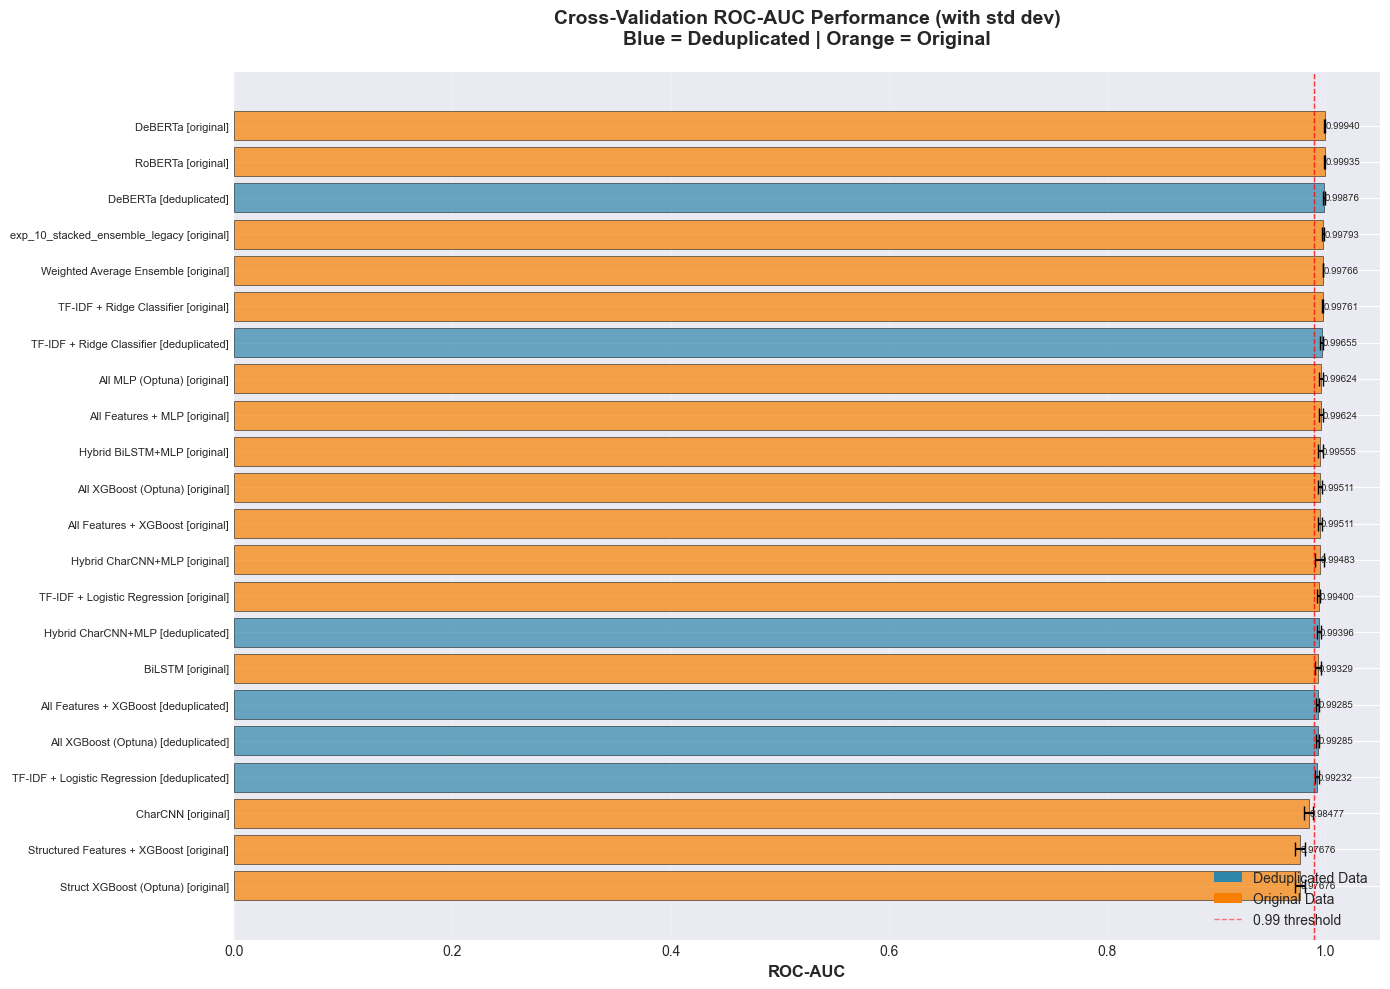


Key Observations:
  - Best CV ROC-AUC: 0.99940 (DeBERTa [original])
  - Most stable (lowest std): Weighted Average Ensemble [original] (±0.00000)

Data Version Impact:
  - Best deduplicated: 0.99876
  - Best original: 0.99940
  - Difference: 0.00064


In [24]:
# Plot CV ROC-AUC with error bars
fig, ax = plt.subplots(figsize=(14, 10))

# Sort by CV ROC-AUC for plotting
plot_df = full_df[full_df['cv_roc_auc'].notna()].sort_values('cv_roc_auc')

y_pos = np.arange(len(plot_df))

# Color by data version: blue for deduplicated, orange for original
colors = ['#2E86AB' if dv == 'deduplicated' else '#F77F00' for dv in plot_df['data_version']]

ax.barh(y_pos, plot_df['cv_roc_auc'], xerr=plot_df['cv_roc_auc_std'], 
        capsize=5, alpha=0.7, color=colors, edgecolor='black', linewidth=0.5)

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df['model_id'], fontsize=8)
ax.set_xlabel('ROC-AUC', fontsize=12, fontweight='bold')
ax.set_title('Cross-Validation ROC-AUC Performance (with std dev)\nBlue = Deduplicated | Orange = Original', 
             fontsize=14, fontweight='bold', pad=20)
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.axvline(x=0.99, color='red', linestyle='--', linewidth=1, alpha=0.5, label='0.99 threshold')

# Add value labels
for i, (idx, row) in enumerate(plot_df.iterrows()):
    ax.text(row['cv_roc_auc'] + 0.001, i, 
            f"{row['cv_roc_auc']:.5f}", 
            va='center', fontsize=7)

# Custom legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2E86AB', label='Deduplicated Data'),
    Patch(facecolor='#F77F00', label='Original Data'),
    ax.axvline(x=0.99, color='red', linestyle='--', linewidth=1, alpha=0.5, label='0.99 threshold')
]
ax.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.show()

print(f"\nKey Observations:")
print(f"  - Best CV ROC-AUC: {plot_df['cv_roc_auc'].max():.5f} ({plot_df.iloc[-1]['model_id']})")
print(f"  - Most stable (lowest std): {plot_df.loc[plot_df['cv_roc_auc_std'].idxmin(), 'model_id']} "
      f"(±{plot_df['cv_roc_auc_std'].min():.5f})")

# Compare dedup vs original
dedup_max = plot_df[plot_df['data_version'] == 'deduplicated']['cv_roc_auc'].max()
orig_max = plot_df[plot_df['data_version'] == 'original']['cv_roc_auc'].max()
print(f"\nData Version Impact:")
print(f"  - Best deduplicated: {dedup_max:.5f}")
print(f"  - Best original: {orig_max:.5f}")
print(f"  - Difference: {abs(dedup_max - orig_max):.5f}")

### 2.3 Fold-Level Variance Analysis

Examine per-fold performance to identify models with high variance (potential overfitting to specific folds).

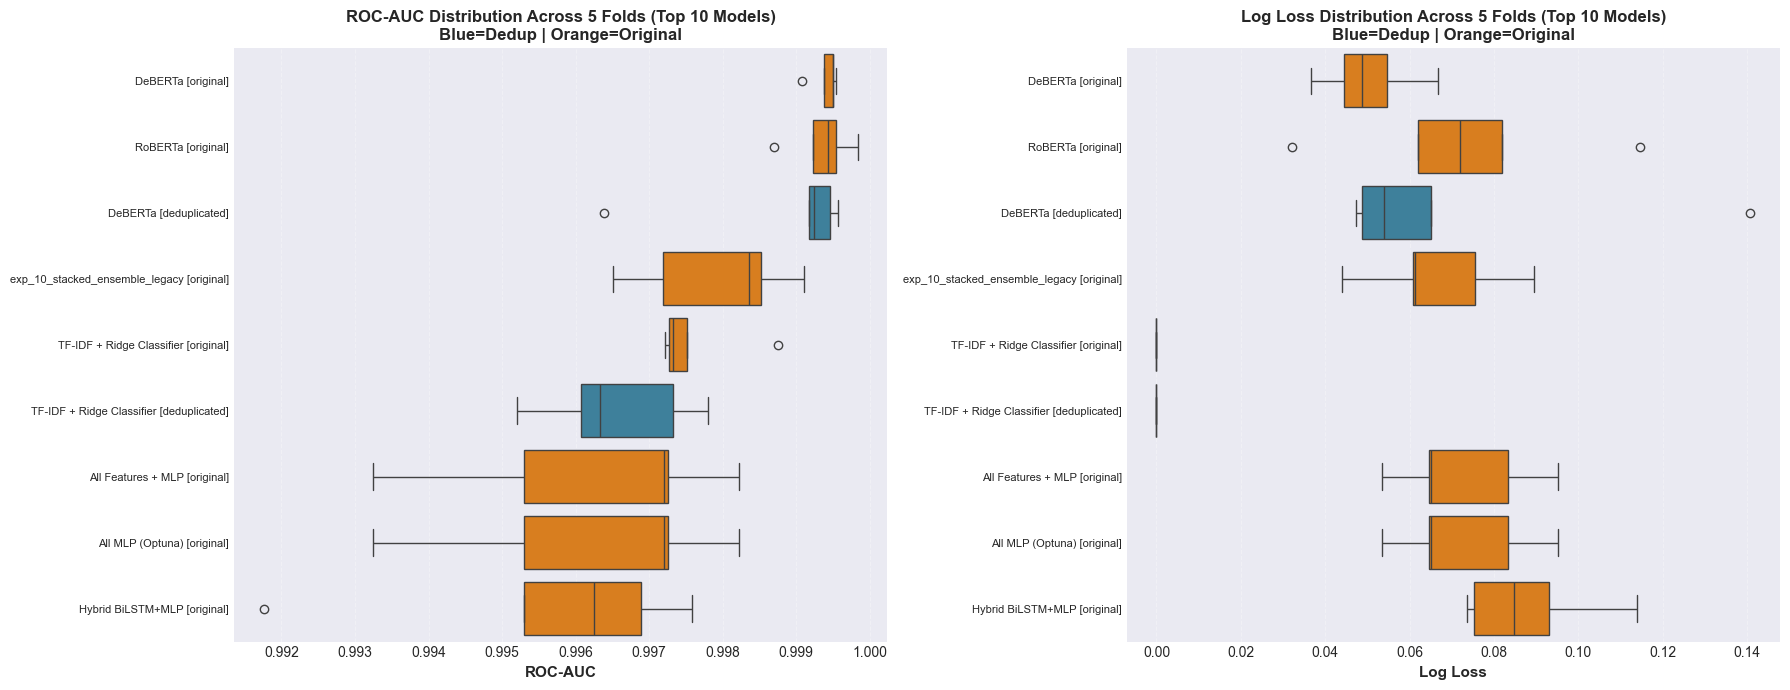


Fold Variance Analysis (sorted by ROC-AUC stability):
                                           roc_auc_mean  roc_auc_std  roc_auc_min  roc_auc_max
model                                                                                         
DeBERTa [original]                             0.999398     0.000185     0.999083     0.999535
RoBERTa [original]                             0.999347     0.000425     0.998695     0.999833
TF-IDF + Ridge Classifier [original]           0.997613     0.000646     0.997218     0.998752
TF-IDF + Ridge Classifier [deduplicated]       0.996547     0.001032     0.995207     0.997803
exp_10_stacked_ensemble_legacy [original]      0.997934     0.001060     0.996507     0.999106
DeBERTa [deduplicated]                         0.998762     0.001340     0.996380     0.999561
All Features + MLP [original]                  0.996241     0.001982     0.993241     0.998217
All MLP (Optuna) [original]                    0.996241     0.001982     0.993241     0.99

In [25]:
# Extract fold-level metrics for top 10 models by CV performance
top_models = full_df.nlargest(10, 'cv_roc_auc')

fold_data = []
for _, row in top_models.iterrows():
    if row['fold_metrics']:
        for fold_metric in row['fold_metrics']:
            fold_data.append({
                'model': row['model_id'],
                'data_version': row['data_version'],
                'fold': fold_metric.get('fold', 0),
                'roc_auc': fold_metric.get('roc_auc', 0),
                'f1': fold_metric.get('f1', 0),
                'log_loss': fold_metric.get('log_loss', 0)
            })

fold_df = pd.DataFrame(fold_data)

# Box plot for ROC-AUC across folds
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# ROC-AUC boxplot
if not fold_df.empty:
    fold_df_sorted = fold_df.sort_values('roc_auc', ascending=False)
    model_order = fold_df_sorted.groupby('model')['roc_auc'].mean().sort_values(ascending=False).index
    
    # Create color palette based on data version
    model_colors = {}
    for model in model_order:
        data_ver = fold_df[fold_df['model'] == model]['data_version'].iloc[0]
        model_colors[model] = '#2E86AB' if data_ver == 'deduplicated' else '#F77F00'
    
    palette = [model_colors[m] for m in model_order]
    
    sns.boxplot(data=fold_df, y='model', x='roc_auc', order=model_order, ax=axes[0], palette=palette)
    axes[0].set_xlabel('ROC-AUC', fontsize=11, fontweight='bold')
    axes[0].set_ylabel('')
    axes[0].set_title('ROC-AUC Distribution Across 5 Folds (Top 10 Models)\nBlue=Dedup | Orange=Original', 
                     fontsize=12, fontweight='bold')
    axes[0].grid(axis='x', alpha=0.3, linestyle='--')
    axes[0].tick_params(axis='y', labelsize=8)
    
    # Log Loss boxplot
    sns.boxplot(data=fold_df, y='model', x='log_loss', order=model_order, ax=axes[1], palette=palette)
    axes[1].set_xlabel('Log Loss', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('')
    axes[1].set_title('Log Loss Distribution Across 5 Folds (Top 10 Models)\nBlue=Dedup | Orange=Original', 
                     fontsize=12, fontweight='bold')
    axes[1].grid(axis='x', alpha=0.3, linestyle='--')
    axes[1].tick_params(axis='y', labelsize=8)

plt.tight_layout()
plt.show()

# Statistical summary
if not fold_df.empty:
    variance_summary = fold_df.groupby('model').agg({
        'roc_auc': ['mean', 'std', 'min', 'max'],
        'log_loss': ['mean', 'std']
    }).round(6)
    variance_summary.columns = ['_'.join(col).strip() for col in variance_summary.columns.values]
    variance_summary = variance_summary.sort_values('roc_auc_std')
    
    print("\nFold Variance Analysis (sorted by ROC-AUC stability):")
    print(variance_summary[['roc_auc_mean', 'roc_auc_std', 'roc_auc_min', 'roc_auc_max']].to_string())
    print(f"\nMost stable model: {variance_summary.index[0]} (std: {variance_summary.iloc[0]['roc_auc_std']:.6f})")

## 3. Kaggle Leaderboard Performance Analysis

Evaluate model performance on the **public leaderboard** (30% of test set). Key considerations:
- Public LB may not be representative of private LB due to limited sample size
- Models should show consistent performance between CV and public LB
- Large gaps may indicate overfitting or distribution shift

### 3.1 Kaggle Leaderboard Rankings

In [26]:
# Kaggle leaderboard summary
kaggle_summary = full_df[full_df['kaggle_roc_auc'].notna()][
    ['model_id', 'model_type', 'data_version', 'kaggle_roc_auc', 'cv_roc_auc', 'cv_roc_auc_std']
].copy()

kaggle_summary = kaggle_summary.sort_values('kaggle_roc_auc', ascending=False)
kaggle_summary['rank'] = range(1, len(kaggle_summary) + 1)

# Reorder columns
kaggle_summary = kaggle_summary[['rank', 'model_id', 'model_type', 'data_version', 'kaggle_roc_auc', 'cv_roc_auc', 'cv_roc_auc_std']]
kaggle_summary.columns = ['Rank', 'Model', 'Type', 'Data', 'Kaggle ROC-AUC', 'CV ROC-AUC', 'CV Std']

print("=" * 140)
print("KAGGLE PUBLIC LEADERBOARD RANKINGS (30% of test set)")
print("=" * 140)
print(kaggle_summary.to_string(index=False))
print("=" * 140)
print(f"\n🏆 Top 3 Models:")
for i, row in kaggle_summary.head(3).iterrows():
    print(f"  {row['Rank']}. {row['Model']:60s} - {row['Kaggle ROC-AUC']:.5f}")
    
print(f"\nScore Statistics:")
print(f"  - Range: {kaggle_summary['Kaggle ROC-AUC'].min():.5f} to {kaggle_summary['Kaggle ROC-AUC'].max():.5f}")
print(f"  - Spread: {kaggle_summary['Kaggle ROC-AUC'].max() - kaggle_summary['Kaggle ROC-AUC'].min():.5f}")

# Compare by data version
dedup_kaggle = kaggle_summary[kaggle_summary['Data'] == 'deduplicated']
orig_kaggle = kaggle_summary[kaggle_summary['Data'] == 'original']

if len(dedup_kaggle) > 0:
    print(f"\nDeduplicated Data:")
    print(f"  - Best: {dedup_kaggle['Kaggle ROC-AUC'].max():.5f}")
    print(f"  - Avg: {dedup_kaggle['Kaggle ROC-AUC'].mean():.5f}")

if len(orig_kaggle) > 0:
    print(f"\nOriginal Data:")
    print(f"  - Best: {orig_kaggle['Kaggle ROC-AUC'].max():.5f}")
    print(f"  - Avg: {orig_kaggle['Kaggle ROC-AUC'].mean():.5f}")

KAGGLE PUBLIC LEADERBOARD RANKINGS (30% of test set)
 Rank                                   Model                                                Type         Data  Kaggle ROC-AUC  CV ROC-AUC   CV Std
    1                      DeBERTa [original]                                          DeBERTa-v3     original         0.99964    0.999398 0.000185
    2                  DeBERTa [deduplicated]                                          DeBERTa-v3 deduplicated         0.99952    0.998762 0.001340
    3             Stacked Ensemble [original] Stacked Ensemble (Logistic Regression Meta-Learner)     original         0.99893         NaN      NaN
    4           Hybrid CharCNN+MLP [original]                        Hybrid CharCNN + MLP (Keras)     original         0.99886    0.994832 0.004155
    5             All MLP (Optuna) [original]                        MLP (Multi-Layer Perceptron)     original         0.99850    0.996241 0.001773
    6         All XGBoost (Optuna) [original]              

### 3.2 Visualization: Kaggle Performance

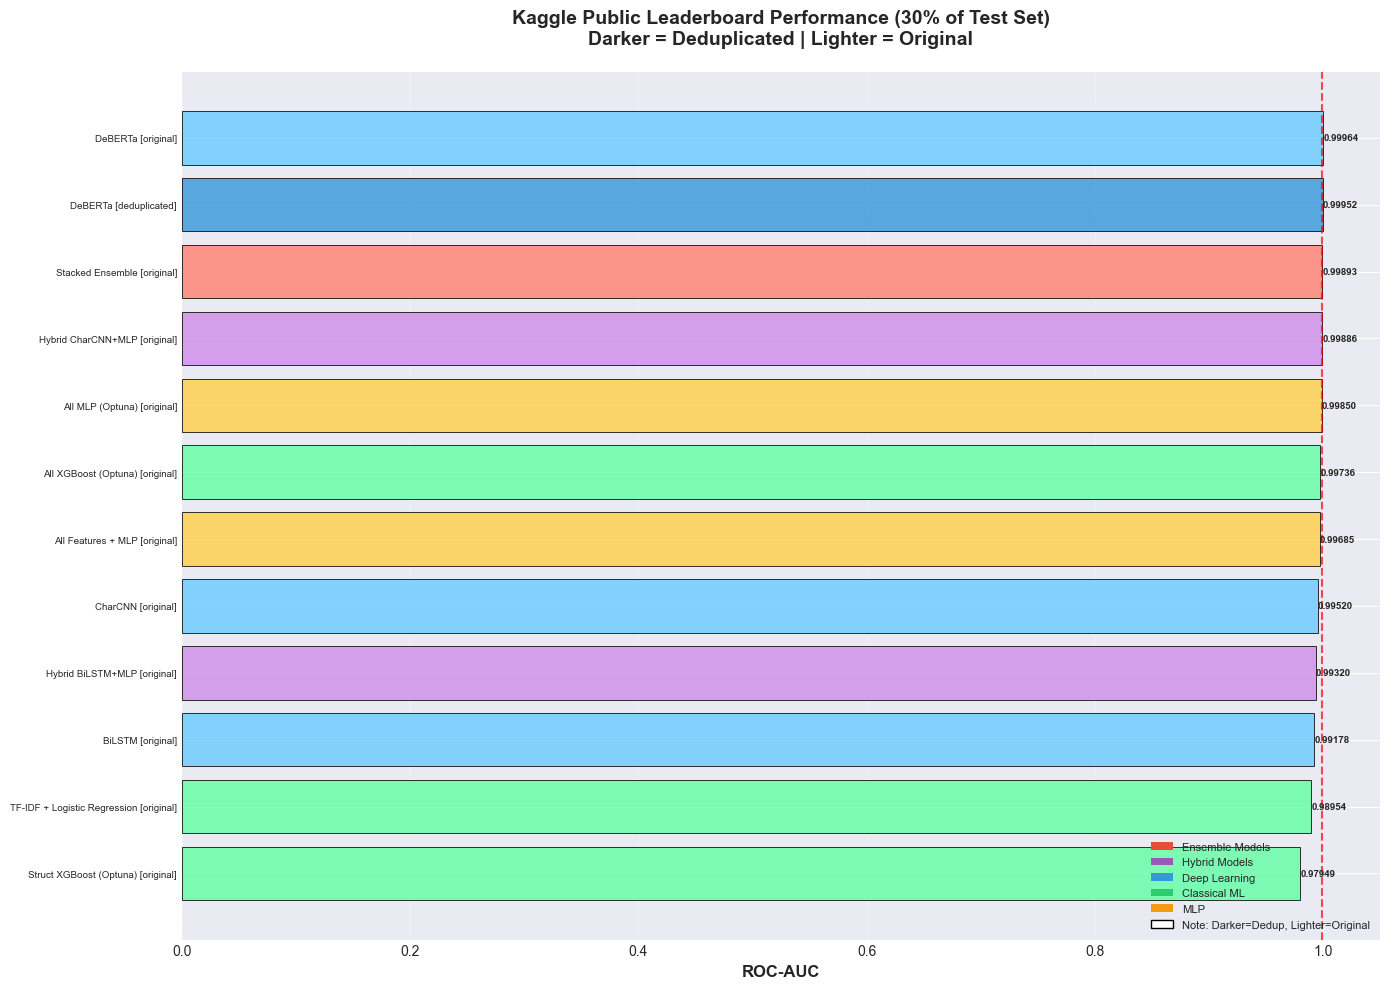


Kaggle Performance Insights:
  - Best submission: DeBERTa [original] (0.99964)
  - 2 models exceed 0.999 ROC-AUC
  - 5 models exceed 0.998 ROC-AUC


In [27]:
# Kaggle performance bar chart
fig, ax = plt.subplots(figsize=(14, 10))

kaggle_plot_df = full_df[full_df['kaggle_roc_auc'].notna()].sort_values('kaggle_roc_auc')

# Create color map based on model family AND data version
def get_model_color(model_name, data_version):
    base_colors = {
        'ensemble': '#e74c3c',  # Red for ensembles
        'hybrid': '#9b59b6',    # Purple for hybrid
        'dl': '#3498db',        # Blue for deep learning
        'ml': '#2ecc71',        # Green for classical ML
        'mlp': '#f39c12',       # Orange for MLP
        'other': '#95a5a6'      # Gray for others
    }
    
    # Determine base family
    model_lower = model_name.lower()
    if 'ensemble' in model_lower or 'stacked' in model_lower or 'weighted' in model_lower:
        base = 'ensemble'
    elif 'hybrid' in model_lower:
        base = 'hybrid'
    elif 'lstm' in model_lower or 'cnn' in model_lower or 'bert' in model_lower:
        base = 'dl'
    elif 'xgboost' in model_lower or 'ridge' in model_lower or 'logreg' in model_lower or 'logistic' in model_lower:
        base = 'ml'
    elif 'mlp' in model_lower:
        base = 'mlp'
    else:
        base = 'other'
    
    # Make original data slightly more transparent or use pattern
    color = base_colors[base]
    if data_version == 'original':
        # Convert hex to RGB and reduce alpha (simulate with lighter shade)
        import matplotlib.colors as mcolors
        rgb = mcolors.hex2color(color)
        # Lighten the color for original data
        rgb = tuple(min(1.0, c + 0.2) for c in rgb)
        return rgb
    return color

colors = [get_model_color(row['display_name'], row['data_version']) for _, row in kaggle_plot_df.iterrows()]

y_pos = np.arange(len(kaggle_plot_df))
ax.barh(y_pos, kaggle_plot_df['kaggle_roc_auc'], alpha=0.8, color=colors, 
        edgecolor='black', linewidth=0.7)

ax.set_yticks(y_pos)
ax.set_yticklabels(kaggle_plot_df['model_id'], fontsize=7)
ax.set_xlabel('ROC-AUC', fontsize=12, fontweight='bold')
ax.set_title('Kaggle Public Leaderboard Performance (30% of Test Set)\nDarker = Deduplicated | Lighter = Original', 
             fontsize=14, fontweight='bold', pad=20)
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.axvline(x=0.999, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='0.999 threshold')

# Add value labels
for i, (idx, row) in enumerate(kaggle_plot_df.iterrows()):
    ax.text(row['kaggle_roc_auc'] + 0.0002, i, 
            f"{row['kaggle_roc_auc']:.5f}", 
            va='center', fontsize=7, fontweight='bold')

# Create legend for model families
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#e74c3c', label='Ensemble Models'),
    Patch(facecolor='#9b59b6', label='Hybrid Models'),
    Patch(facecolor='#3498db', label='Deep Learning'),
    Patch(facecolor='#2ecc71', label='Classical ML'),
    Patch(facecolor='#f39c12', label='MLP'),
    Patch(facecolor='white', edgecolor='black', label='Note: Darker=Dedup, Lighter=Original')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()

print(f"\nKaggle Performance Insights:")
print(f"  - Best submission: {kaggle_plot_df.iloc[-1]['model_id']} ({kaggle_plot_df['kaggle_roc_auc'].max():.5f})")
print(f"  - {len(kaggle_plot_df[kaggle_plot_df['kaggle_roc_auc'] > 0.999])} models exceed 0.999 ROC-AUC")
print(f"  - {len(kaggle_plot_df[kaggle_plot_df['kaggle_roc_auc'] > 0.998])} models exceed 0.998 ROC-AUC")

## 4. Generalization Analysis: CV vs Kaggle

Compare cross-validation performance with Kaggle leaderboard scores to assess:
- **Generalization capability**: How well models transfer to unseen data
- **Overfitting indicators**: Large positive gaps (CV > Kaggle) suggest overfitting to training folds
- **Underfitting indicators**: Large negative gaps (CV < Kaggle) may indicate lucky test split or model instability

### 4.3 Submission Predictions Correlation Heatmap

Analyze the correlation between predictions from different submission files to understand model diversity and agreement.

Found 30 submission files
  - From experiments/: 9
  - From experiments_old/: 21
Successfully loaded 28 submission files


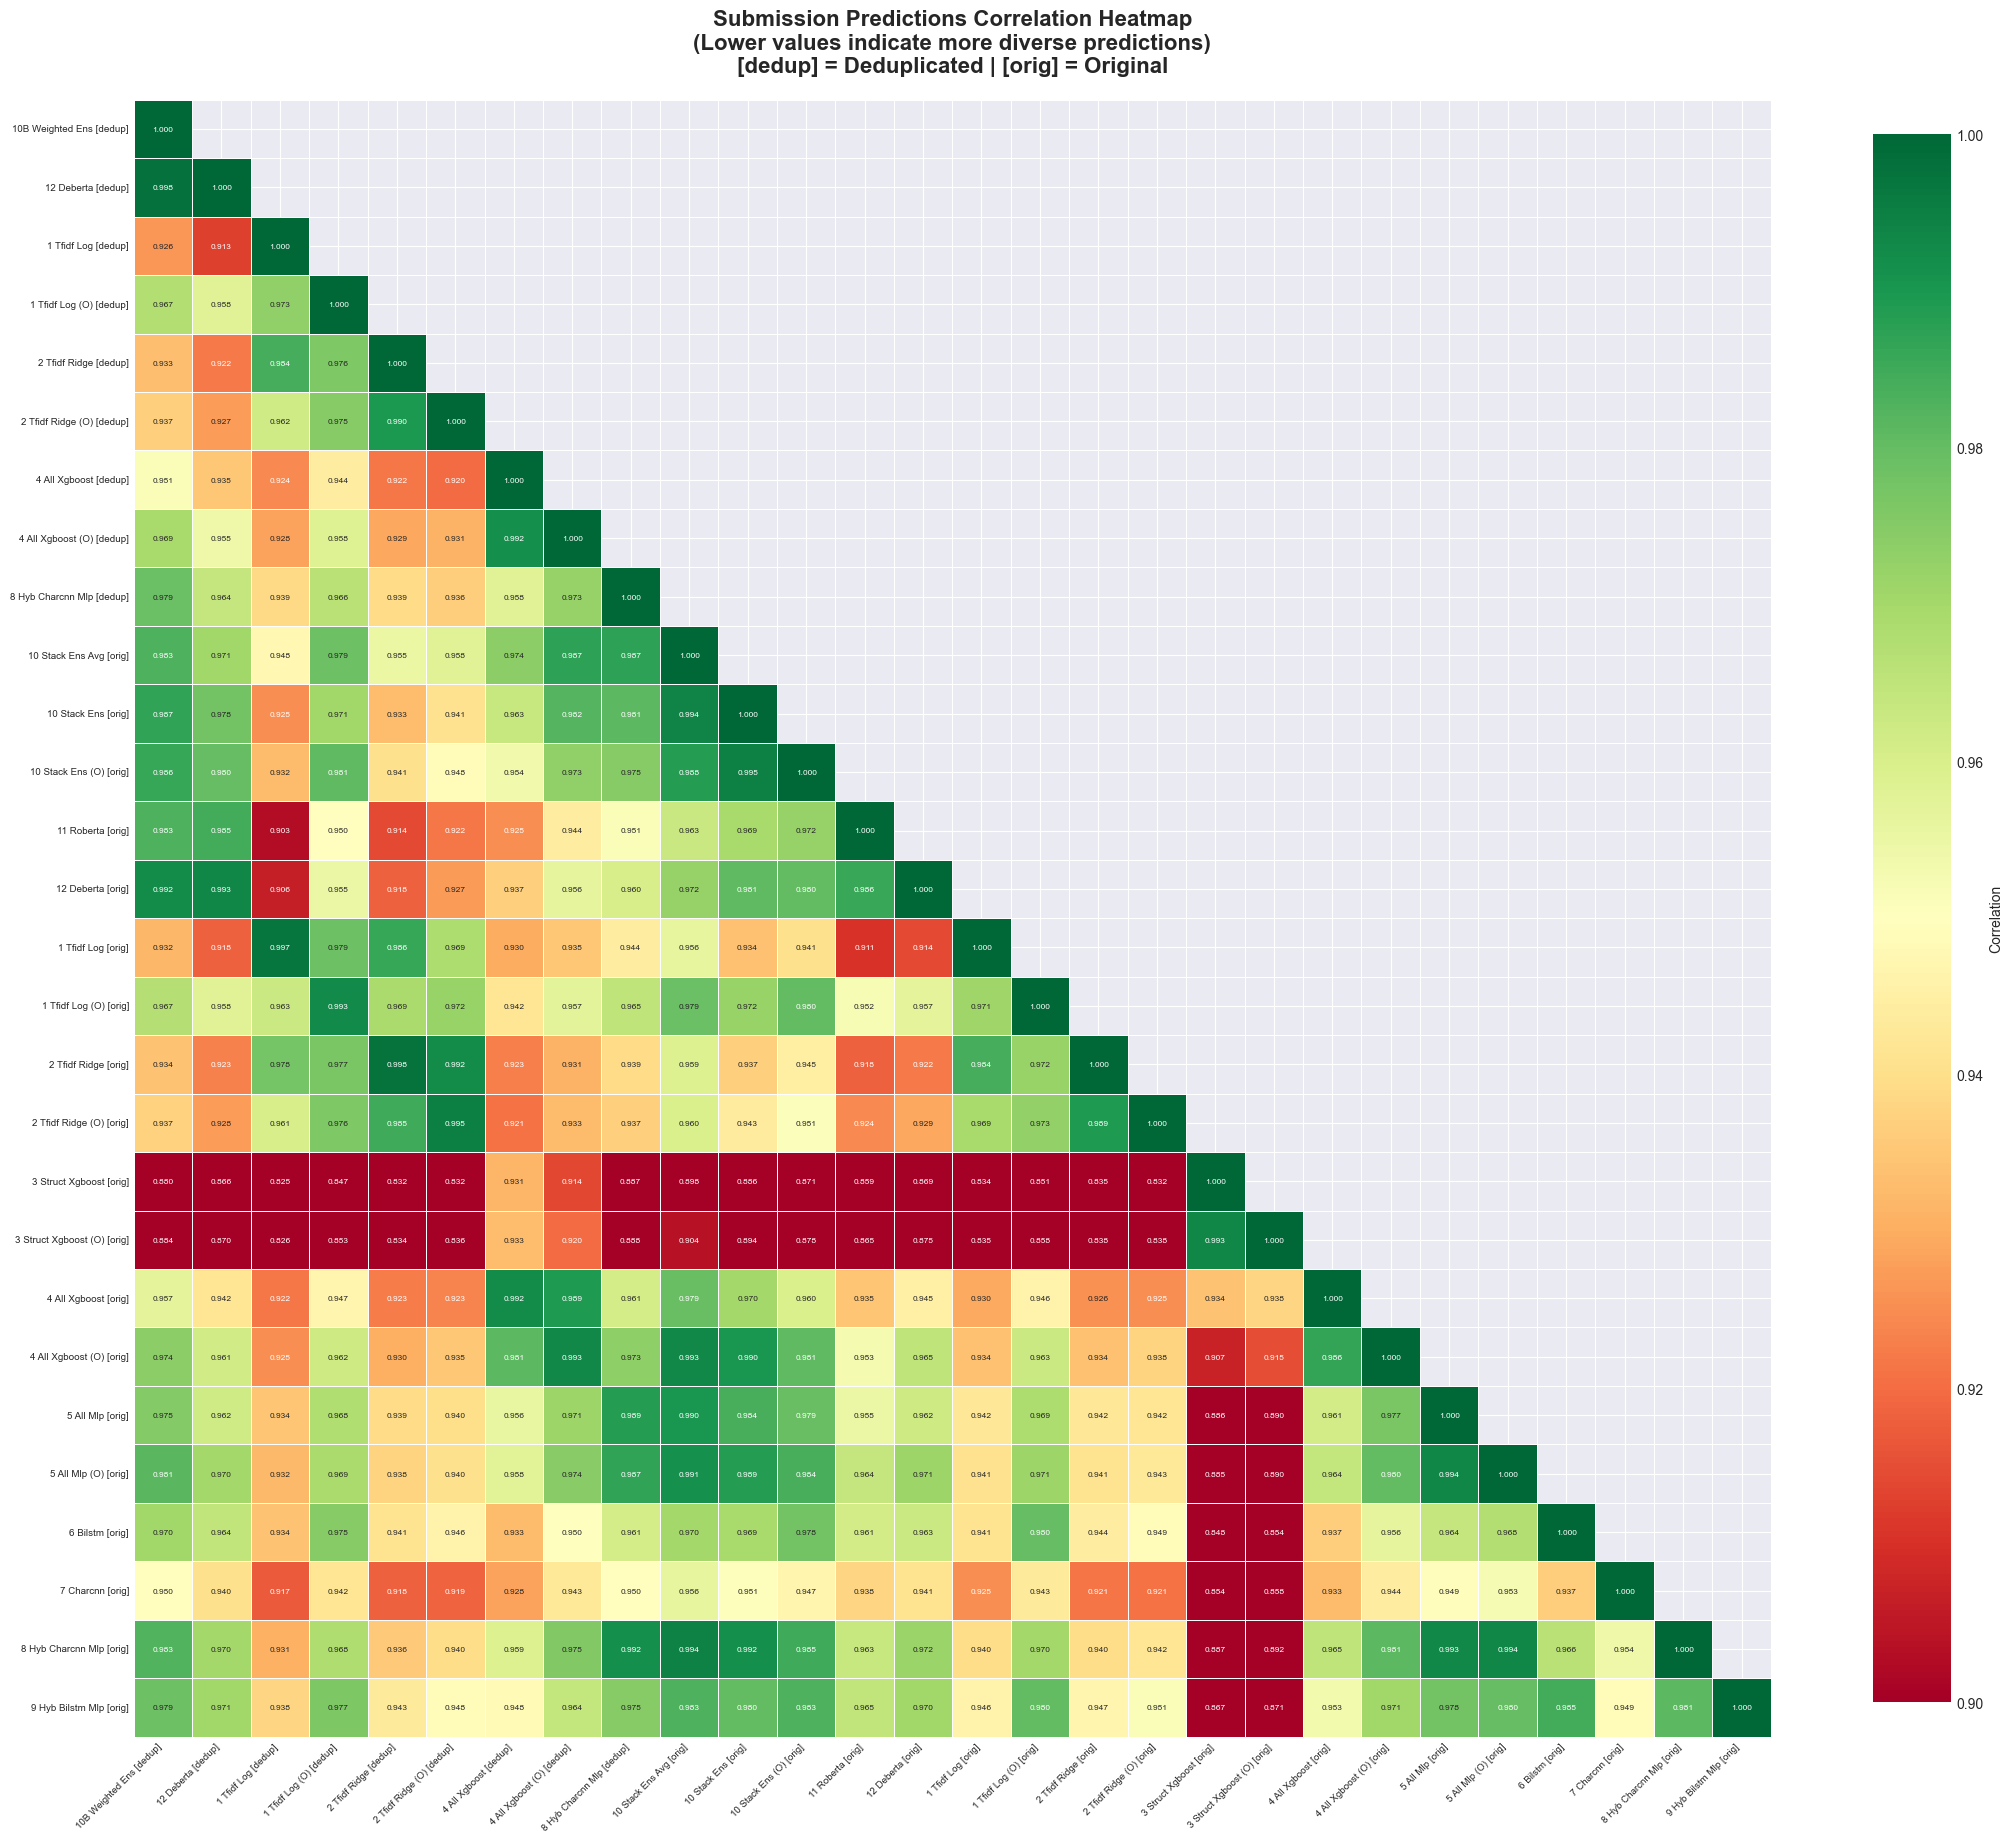


SUBMISSION CORRELATION ANALYSIS

🔍 Most Diverse Model Pairs (Lowest Correlations):
----------------------------------------------------------------------------------------------------
 1. 3 Struct Xgboost [orig]                            <-> 1 Tfidf Log [dedup]                                : 0.825309
 2. 3 Struct Xgboost (O) [orig]                        <-> 1 Tfidf Log [dedup]                                : 0.825559
 3. 3 Struct Xgboost [orig]                            <-> 2 Tfidf Ridge (O) [dedup]                          : 0.831636
 4. 3 Struct Xgboost [orig]                            <-> 2 Tfidf Ridge (O) [orig]                           : 0.831642
 5. 3 Struct Xgboost [orig]                            <-> 2 Tfidf Ridge [dedup]                              : 0.832437
 6. 3 Struct Xgboost [orig]                            <-> 1 Tfidf Log [orig]                                 : 0.833671
 7. 3 Struct Xgboost (O) [orig]                        <-> 2 Tfidf Ridge [dedup]         

In [28]:
# Load all submission CSV files from both directories and create correlation heatmap
import glob
from pathlib import Path

# Find all submission CSV files (excluding sample_submission) from both directories
submission_files_exp = sorted(glob.glob('experiments/**/exp_*_submission*.csv', recursive=True))
submission_files_old = sorted(glob.glob('experiments_old/**/exp_*_submission*.csv', recursive=True))
submission_files = submission_files_exp + submission_files_old
submission_files = [f for f in submission_files if 'sample_submission' not in f]

print(f"Found {len(submission_files)} submission files")
print(f"  - From experiments/: {len(submission_files_exp)}")
print(f"  - From experiments_old/: {len(submission_files_old)}")

# Load predictions from each submission file
predictions_dict = {}
for filepath in submission_files:
    try:
        # Extract model name and source from filepath
        path_obj = Path(filepath)
        filename = path_obj.stem  # e.g., 'exp_11_roberta_submission'
        
        # Determine source
        if 'experiments_old' in filepath:
            source = 'orig'
        else:
            source = 'dedup'
        
        # Load the submission file
        sub_df = pd.read_csv(filepath)
        
        # Assuming the submission format has 'id' and 'target' or 'probability' columns
        # Store predictions with a cleaner name including source
        if 'target' in sub_df.columns:
            predictions_dict[f"{filename} [{source}]"] = sub_df['target'].values
        elif 'probability' in sub_df.columns:
            predictions_dict[f"{filename} [{source}]"] = sub_df['probability'].values
        elif len(sub_df.columns) > 1:
            # Use second column if 'target'/'probability' not found
            predictions_dict[f"{filename} [{source}]"] = sub_df.iloc[:, 1].values
    except Exception as e:
        print(f"Error loading {filepath}: {e}")

print(f"Successfully loaded {len(predictions_dict)} submission files")

# Create DataFrame with all predictions
if len(predictions_dict) > 0:
    predictions_df = pd.DataFrame(predictions_dict)
    
    # Calculate correlation matrix
    correlation_matrix = predictions_df.corr()
    
    # Create a more readable name mapping
    def clean_name(filename):
        # Keep the source indicator [dedup] or [orig]
        if '[' in filename:
            name_part, source_part = filename.rsplit('[', 1)
            source = '[' + source_part  # Keep [dedup] or [orig]
        else:
            name_part = filename
            source = ''
        
        # Remove 'exp_' prefix and '_submission' suffix
        name = name_part.replace('exp_', '').replace('_submission', '').strip()
        # Replace underscores with spaces and capitalize
        name = name.replace('_', ' ').title()
        # Shorten common terms
        name = name.replace('Optuna', '(O)').replace('Hybrid', 'Hyb')
        name = name.replace('Ensemble', 'Ens').replace('Stacked', 'Stack')
        return name + ' ' + source
    
    # Apply name cleaning
    correlation_matrix.index = [clean_name(idx) for idx in correlation_matrix.index]
    correlation_matrix.columns = [clean_name(col) for col in correlation_matrix.columns]
    
    # Create heatmap
    fig, ax = plt.subplots(figsize=(22, 20))
    
    # Create mask for upper triangle (optional - shows only lower triangle)
    mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1)
    
    # Plot heatmap
    sns.heatmap(correlation_matrix, 
                mask=mask,
                annot=True,  # Show correlation values
                fmt='.3f',  # Format to 3 decimal places
                cmap='RdYlGn',  # Red-Yellow-Green colormap
                center=0.95,  # Center colormap at 0.95 (since most correlations will be high)
                vmin=0.90,  # Minimum value for colormap
                vmax=1.0,   # Maximum value
                square=True,
                linewidths=0.5,
                cbar_kws={"shrink": 0.8, "label": "Correlation"},
                ax=ax,
                annot_kws={"size": 6})
    
    ax.set_title('Submission Predictions Correlation Heatmap\n(Lower values indicate more diverse predictions)\n[dedup] = Deduplicated | [orig] = Original', 
                 fontsize=16, fontweight='bold', pad=20)
    
    # Rotate labels for better readability
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=7)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=7)
    
    plt.tight_layout()
    plt.show()
    
    # Analysis of correlation patterns
    print("\n" + "=" * 100)
    print("SUBMISSION CORRELATION ANALYSIS")
    print("=" * 100)
    
    # Find pairs with lowest correlation (most diverse)
    # Get lower triangle indices
    lower_tri_indices = np.tril_indices_from(correlation_matrix, k=-1)
    lower_tri_corrs = correlation_matrix.values[lower_tri_indices]
    
    # Sort correlations
    sorted_indices = np.argsort(lower_tri_corrs)
    
    print("\n🔍 Most Diverse Model Pairs (Lowest Correlations):")
    print("-" * 100)
    for i in range(min(10, len(sorted_indices))):
        idx = sorted_indices[i]
        row_idx = lower_tri_indices[0][idx]
        col_idx = lower_tri_indices[1][idx]
        corr_value = lower_tri_corrs[idx]
        model1 = correlation_matrix.index[row_idx]
        model2 = correlation_matrix.columns[col_idx]
        print(f"{i+1:2d}. {model1:50s} <-> {model2:50s} : {corr_value:.6f}")
    
    print("\n🤝 Most Similar Model Pairs (Highest Correlations - excluding 1.0):")
    print("-" * 100)
    # Filter out perfect correlations (same model)
    non_perfect = lower_tri_corrs[lower_tri_corrs < 0.9999]
    if len(non_perfect) > 0:
        sorted_high_indices = np.argsort(lower_tri_corrs)[::-1]
        count = 0
        for idx in sorted_high_indices:
            corr_value = lower_tri_corrs[idx]
            if corr_value < 0.9999:  # Skip perfect correlations
                row_idx = lower_tri_indices[0][idx]
                col_idx = lower_tri_indices[1][idx]
                model1 = correlation_matrix.index[row_idx]
                model2 = correlation_matrix.columns[col_idx]
                count += 1
                print(f"{count:2d}. {model1:50s} <-> {model2:50s} : {corr_value:.6f}")
                if count >= 10:
                    break
    
    print("\nSummary Statistics:")
    print("-" * 100)
    print(f"• Total models compared: {len(correlation_matrix)}")
    print(f"• Average correlation: {lower_tri_corrs.mean():.6f}")
    print(f"• Median correlation: {np.median(lower_tri_corrs):.6f}")
    print(f"• Std dev: {lower_tri_corrs.std():.6f}")
    print(f"• Min correlation: {lower_tri_corrs.min():.6f}")
    print(f"• Max correlation (non-perfect): {lower_tri_corrs[lower_tri_corrs < 0.9999].max():.6f}")
    
    print("\nInsights for Ensemble Building:")
    print("-" * 100)
    avg_corr = lower_tri_corrs.mean()
    if avg_corr > 0.98:
        print("• High average correlation suggests limited model diversity")
        print("• Models are making very similar predictions")
        print("• Ensemble gains may be modest")
        print("• Consider including the most diverse models identified above")
    elif avg_corr > 0.95:
        print("• ✓ Moderate correlation indicates reasonable model diversity")
        print("• Ensemble of diverse models likely to improve performance")
        print("• Focus on combining models with correlations < 0.95")
    else:
        print("• ✓✓ Good model diversity detected")
        print("• Strong potential for ensemble improvements")
        print("• Combine diverse models for robust predictions")
    
    # Identify model clusters (if correlations vary significantly)
    if lower_tri_corrs.std() > 0.01:
        print("\n• Different model families show varying agreement levels")
        print("• Consider stratified ensemble based on model types")
    
    print("\n• Compare deduplicated vs original data models for potential ensemble")
    
    print("=" * 100)
    
else:
    print("No submission files loaded successfully")

### 4.1 Scatter Plot: CV vs Kaggle Performance

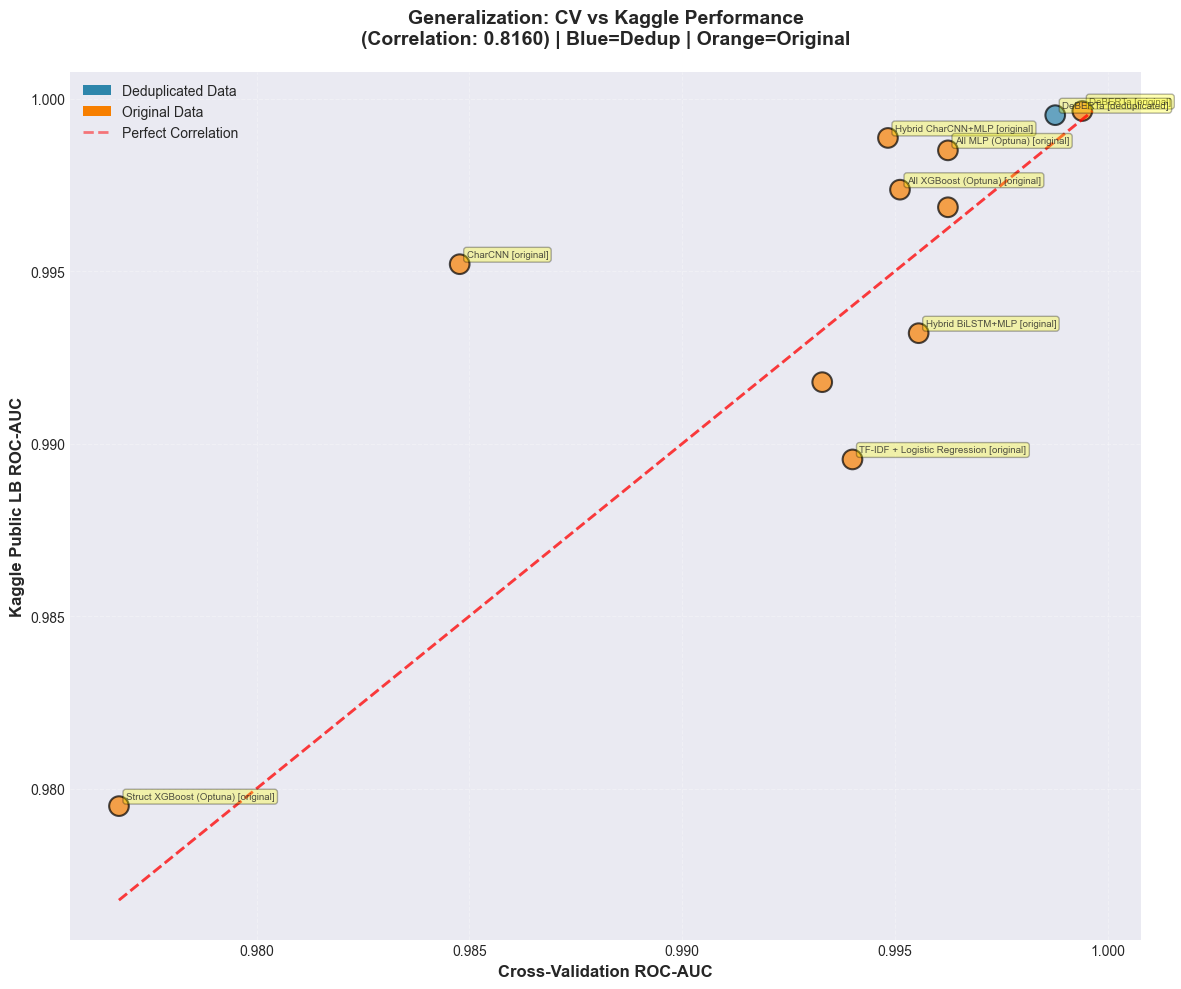


Correlation Analysis:
  - Pearson correlation: 0.8160
  - Strong correlation between CV and Kaggle

  Interpretation:
    ✓ High correlation suggests CV is a reliable indicator of test performance


In [29]:
# Scatter plot: CV vs Kaggle ROC-AUC
fig, ax = plt.subplots(figsize=(12, 10))

comparison_df = full_df[full_df['kaggle_roc_auc'].notna()].copy()

# Color by data version: blue for deduplicated, orange for original
colors = ['#2E86AB' if dv == 'deduplicated' else '#F77F00' for dv in comparison_df['data_version']]

scatter = ax.scatter(comparison_df['cv_roc_auc'], 
                     comparison_df['kaggle_roc_auc'],
                     s=200, alpha=0.7, c=colors, 
                     edgecolors='black', linewidth=1.5)

# Add perfect correlation line
min_val = min(comparison_df['cv_roc_auc'].min(), comparison_df['kaggle_roc_auc'].min())
max_val = max(comparison_df['cv_roc_auc'].max(), comparison_df['kaggle_roc_auc'].max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, alpha=0.5, label='Perfect Correlation')

# Add labels for each point
for idx, row in comparison_df.iterrows():
    # Only label top models and outliers
    if row['kaggle_roc_auc'] > 0.998 or abs(row['generalization_gap']) > 0.002:
        ax.annotate(row['model_id'], 
                   (row['cv_roc_auc'], row['kaggle_roc_auc']),
                   xytext=(5, 5), textcoords='offset points',
                   fontsize=7, alpha=0.8,
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.3))

# Calculate correlation
correlation = comparison_df[['cv_roc_auc', 'kaggle_roc_auc']].corr().iloc[0, 1]

ax.set_xlabel('Cross-Validation ROC-AUC', fontsize=12, fontweight='bold')
ax.set_ylabel('Kaggle Public LB ROC-AUC', fontsize=12, fontweight='bold')
ax.set_title(f'Generalization: CV vs Kaggle Performance\n(Correlation: {correlation:.4f}) | Blue=Dedup | Orange=Original', 
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')

# Update legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2E86AB', label='Deduplicated Data'),
    Patch(facecolor='#F77F00', label='Original Data'),
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, alpha=0.5, label='Perfect Correlation')[0]
]
ax.legend(handles=legend_elements, fontsize=10)

plt.tight_layout()
plt.show()

print(f"\nCorrelation Analysis:")
print(f"  - Pearson correlation: {correlation:.4f}")
print(f"  - {'Strong' if correlation > 0.7 else 'Moderate' if correlation > 0.4 else 'Weak'} correlation between CV and Kaggle")
print(f"\n  Interpretation:")
if correlation > 0.7:
    print(f"    ✓ High correlation suggests CV is a reliable indicator of test performance")
else:
    print(f"    ⚠ Moderate/low correlation - public LB may not be fully representative")

### 4.2 Generalization Gap Analysis

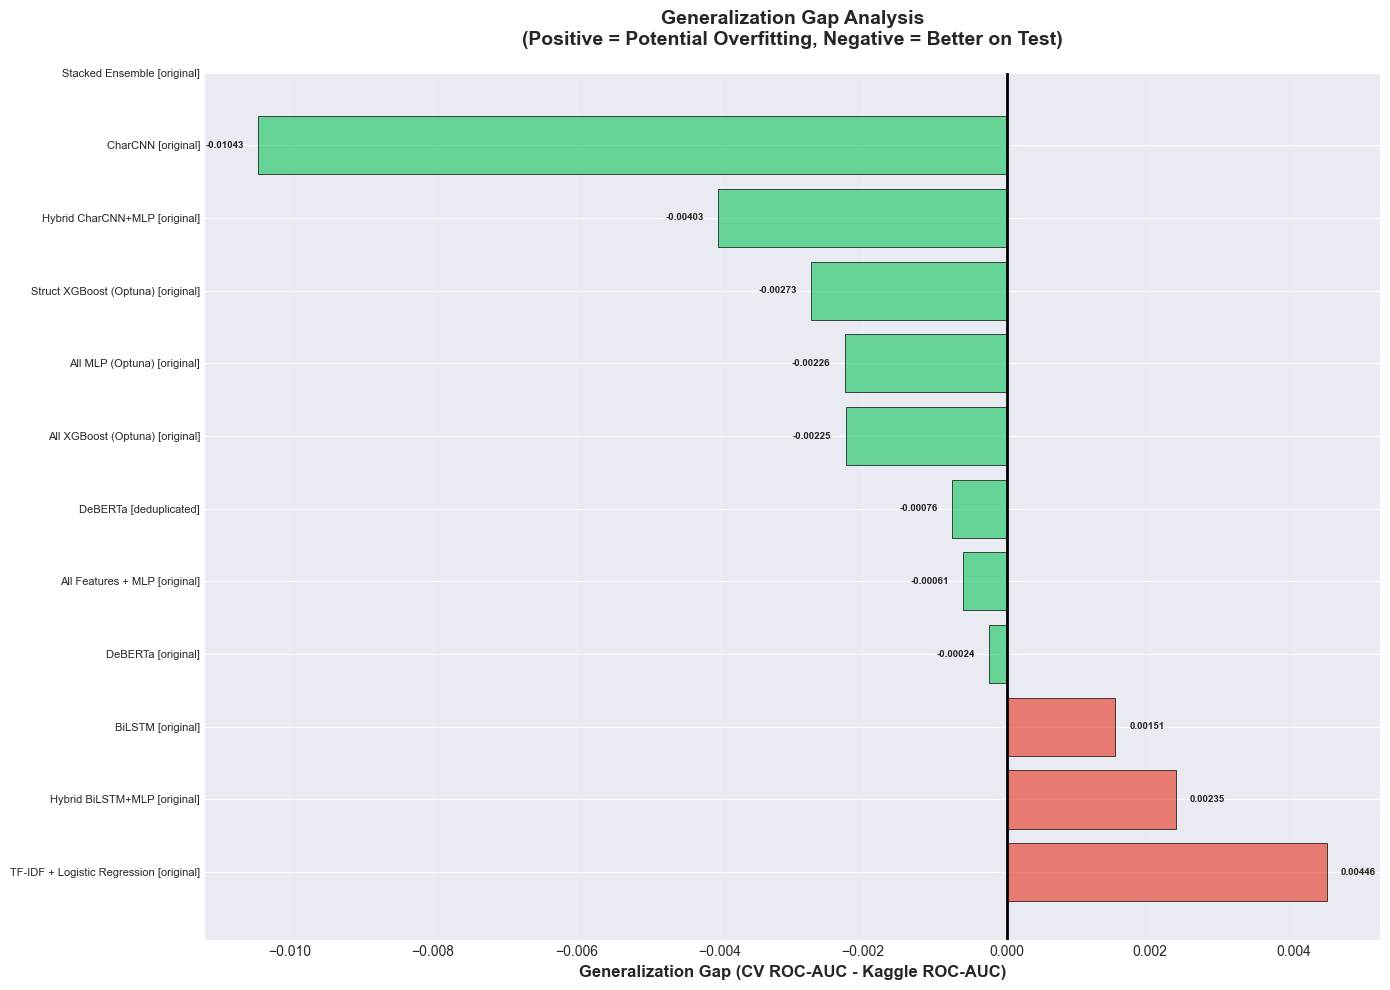


Generalization Gap Statistics:
  - Mean gap: -0.001362
  - Median gap: -0.000758
  - Std dev: 0.003884

  Models with negative gap (better on test): 8
  Models with positive gap (better on CV): 3

Best generalizers (most negative gap):

Worst generalizers (most positive gap):

Data Version Comparison:
  Deduplicated - Avg gap: -0.000758, Std: nan
  Original - Avg gap: -0.001422, Std: 0.004089


In [30]:
# Generalization gap: CV - Kaggle (positive = overfit, negative = underfit/lucky)
gap_df = comparison_df[['model_id', 'data_version', 'cv_roc_auc', 'kaggle_roc_auc', 'generalization_gap']].copy()
gap_df = gap_df.sort_values('generalization_gap', ascending=False)

fig, ax = plt.subplots(figsize=(14, 10))

# Color bars: red for positive gap (overfit), green for negative (underfit)
colors = ['#e74c3c' if gap > 0 else '#2ecc71' for gap in gap_df['generalization_gap']]

y_pos = np.arange(len(gap_df))
bars = ax.barh(y_pos, gap_df['generalization_gap'], alpha=0.7, color=colors, edgecolor='black', linewidth=0.7)

ax.set_yticks(y_pos)
ax.set_yticklabels(gap_df['model_id'], fontsize=8)
ax.set_xlabel('Generalization Gap (CV ROC-AUC - Kaggle ROC-AUC)', fontsize=12, fontweight='bold')
ax.set_title('Generalization Gap Analysis\n(Positive = Potential Overfitting, Negative = Better on Test)', 
             fontsize=14, fontweight='bold', pad=20)
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.axvline(x=0, color='black', linewidth=2, linestyle='-')

# Add value labels
for i, (idx, row) in enumerate(gap_df.iterrows()):
    label = f"{row['generalization_gap']:.5f}"
    x_pos = row['generalization_gap'] + (0.0002 if row['generalization_gap'] > 0 else -0.0002)
    ha = 'left' if row['generalization_gap'] > 0 else 'right'
    ax.text(x_pos, i, label, va='center', ha=ha, fontsize=7, fontweight='bold')

plt.tight_layout()
plt.show()

# Statistical summary
print(f"\nGeneralization Gap Statistics:")
print(f"  - Mean gap: {gap_df['generalization_gap'].mean():.6f}")
print(f"  - Median gap: {gap_df['generalization_gap'].median():.6f}")
print(f"  - Std dev: {gap_df['generalization_gap'].std():.6f}")
print(f"\n  Models with negative gap (better on test): {len(gap_df[gap_df['generalization_gap'] < 0])}")
print(f"  Models with positive gap (better on CV): {len(gap_df[gap_df['generalization_gap'] > 0])}")

print(f"\nBest generalizers (most negative gap):")
for i, row in gap_df.head(3).iterrows():
    if row['generalization_gap'] < 0:
        print(f"    • {row['model_id']:60s} Gap: {row['generalization_gap']:.6f}")

print(f"\nWorst generalizers (most positive gap):")
for i, row in gap_df.tail(3).iterrows():
    if row['generalization_gap'] > 0:
        print(f"    • {row['model_id']:60s} Gap: {row['generalization_gap']:.6f}")

# Compare by data version
dedup_gap = gap_df[gap_df['data_version'] == 'deduplicated']['generalization_gap']
orig_gap = gap_df[gap_df['data_version'] == 'original']['generalization_gap']

if len(dedup_gap) > 0 and len(orig_gap) > 0:
    print(f"\nData Version Comparison:")
    print(f"  Deduplicated - Avg gap: {dedup_gap.mean():.6f}, Std: {dedup_gap.std():.6f}")
    print(f"  Original - Avg gap: {orig_gap.mean():.6f}, Std: {orig_gap.std():.6f}")

## 5. Model Architecture Comparison

Compare different modeling approaches by family to understand architectural trade-offs.

### 5.1 Model Family Performance

MODEL FAMILY PERFORMANCE COMPARISON
                          cv_roc_auc_mean  cv_roc_auc_std  cv_roc_auc_max  kaggle_roc_auc_mean  kaggle_roc_auc_std  kaggle_roc_auc_max  generalization_gap_mean  generalization_gap_std
family                                                                                                                                                                                 
Transformer (BERT)               0.999080        0.000450        0.999398             0.999580            0.000085             0.99964                -0.000500                0.000365
Ensemble                              NaN             NaN             NaN             0.998930                 NaN             0.99893                      NaN                     NaN
Neural Network (MLP)             0.996241        0.000000        0.996241             0.997675            0.001167             0.99850                -0.001434                0.001167
Hybrid (DL + Features)           0.995192   

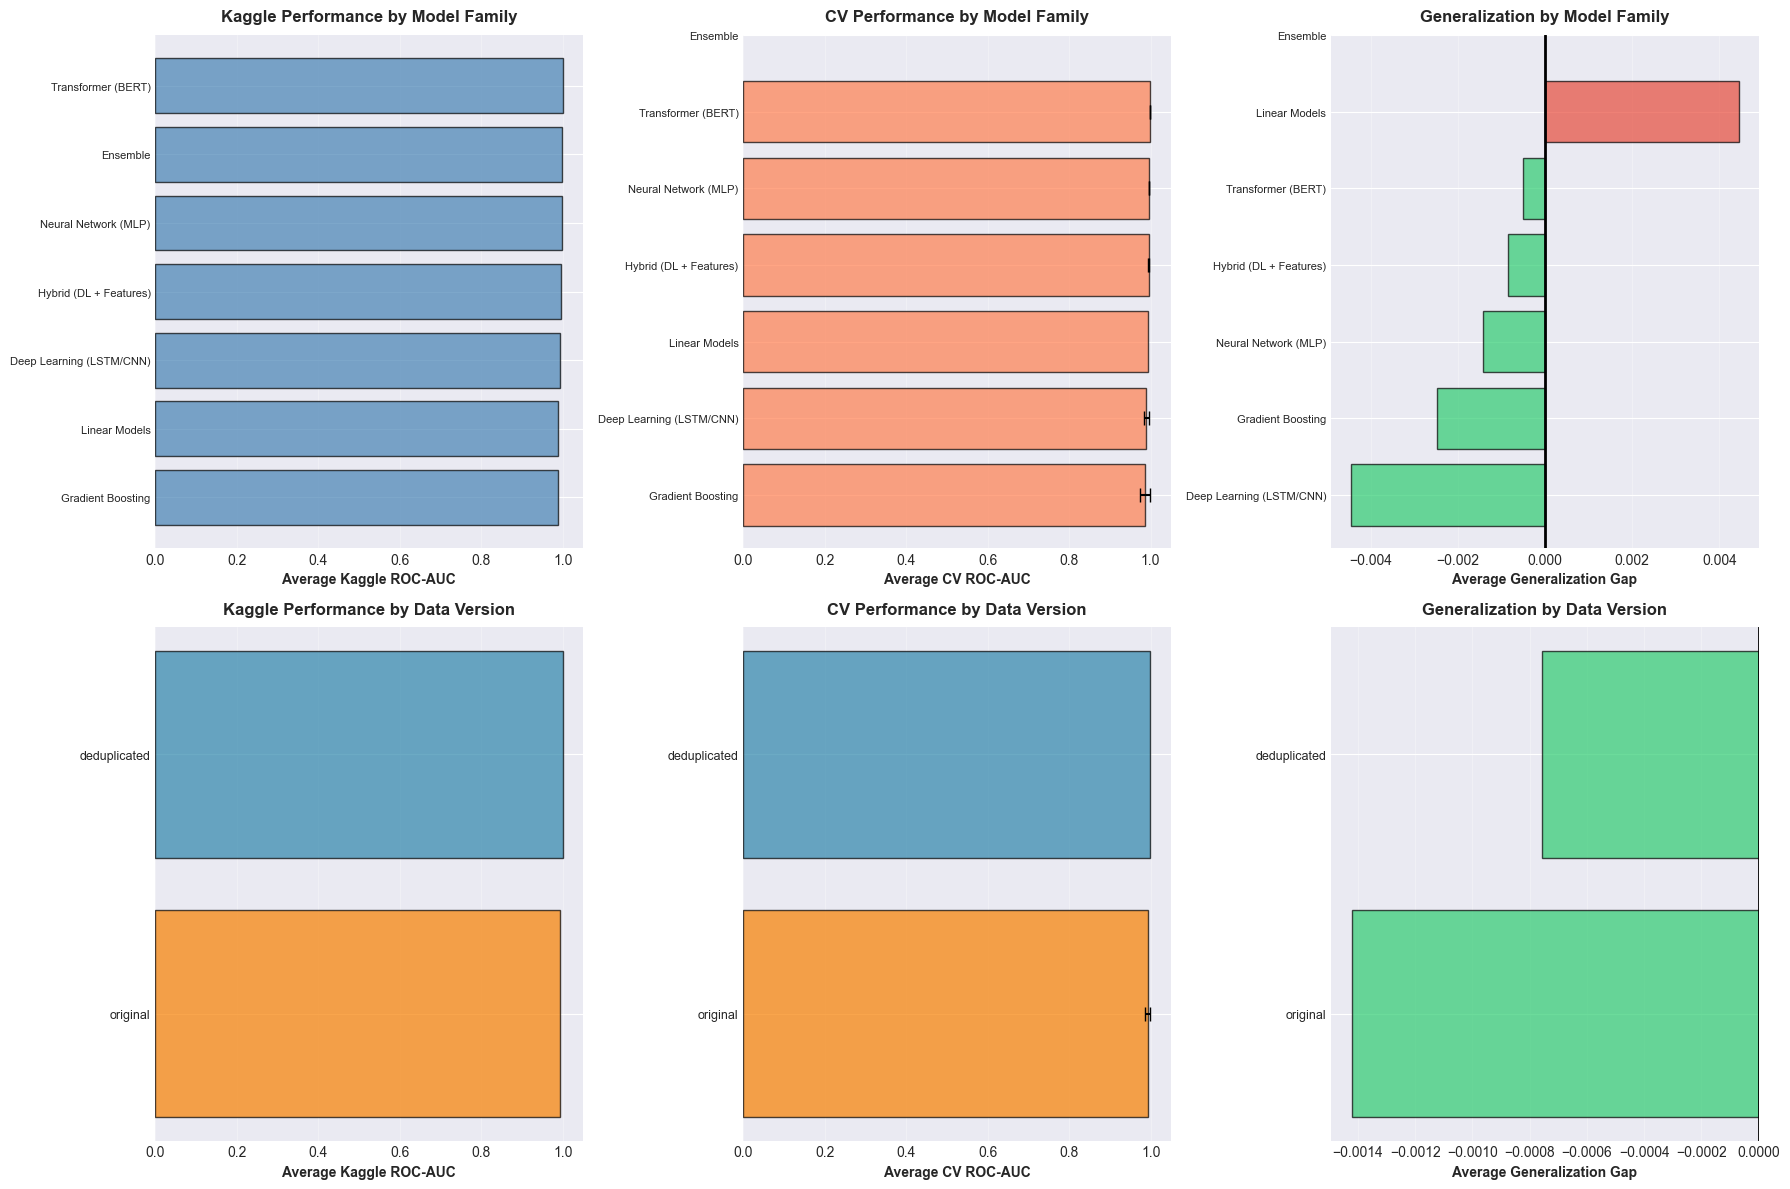


Key Insights:

  By Model Family:
    - Best family (Kaggle): Transformer (BERT) (0.99958)
    - Best family (CV): Transformer (BERT) (0.99908)
    - Most consistent family: Neural Network (MLP) (std: 0.000000)

  By Data Version:
    - Deduplicated avg: 0.99952
    - Original avg: 0.99449
    - Difference: 0.00503
    - ✓ Deduplication improved performance


In [31]:
# Categorize models by family
def categorize_model(name):
    name_lower = name.lower()
    if 'ensemble' in name_lower or 'stacked' in name_lower or 'weighted' in name_lower:
        return 'Ensemble'
    elif 'hybrid' in name_lower:
        return 'Hybrid (DL + Features)'
    elif 'lstm' in name_lower or 'cnn' in name_lower:
        return 'Deep Learning (LSTM/CNN)'
    elif 'bert' in name_lower or 'roberta' in name_lower or 'deberta' in name_lower:
        return 'Transformer (BERT)'
    elif 'xgboost' in name_lower:
        return 'Gradient Boosting'
    elif 'mlp' in name_lower:
        return 'Neural Network (MLP)'
    elif 'ridge' in name_lower or 'logreg' in name_lower or 'logistic' in name_lower:
        return 'Linear Models'
    else:
        return 'Other'

comparison_df['family'] = comparison_df['display_name'].apply(categorize_model)

# Family-level statistics
family_stats = comparison_df.groupby('family').agg({
    'cv_roc_auc': ['mean', 'std', 'max'],
    'kaggle_roc_auc': ['mean', 'std', 'max'],
    'generalization_gap': ['mean', 'std']
}).round(6)

family_stats.columns = ['_'.join(col).strip() for col in family_stats.columns.values]
family_stats = family_stats.sort_values('kaggle_roc_auc_mean', ascending=False)

print("=" * 100)
print("MODEL FAMILY PERFORMANCE COMPARISON")
print("=" * 100)
print(family_stats.to_string())
print("=" * 100)

# Also analyze by data version
print("\nPERFORMANCE BY DATA VERSION")
print("=" * 100)
data_stats = comparison_df.groupby('data_version').agg({
    'cv_roc_auc': ['mean', 'std', 'max'],
    'kaggle_roc_auc': ['mean', 'std', 'max'],
    'generalization_gap': ['mean', 'std']
}).round(6)
data_stats.columns = ['_'.join(col).strip() for col in data_stats.columns.values]
print(data_stats.to_string())
print("=" * 100)

# Visualization
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Plot 1: Average Kaggle ROC-AUC by family
family_kaggle = comparison_df.groupby('family')['kaggle_roc_auc'].mean().sort_values()
axes[0, 0].barh(range(len(family_kaggle)), family_kaggle.values, color='steelblue', alpha=0.7, edgecolor='black')
axes[0, 0].set_yticks(range(len(family_kaggle)))
axes[0, 0].set_yticklabels(family_kaggle.index, fontsize=8)
axes[0, 0].set_xlabel('Average Kaggle ROC-AUC', fontweight='bold')
axes[0, 0].set_title('Kaggle Performance by Model Family', fontweight='bold', pad=10)
axes[0, 0].grid(axis='x', alpha=0.3)

# Plot 2: CV ROC-AUC by family (with std as error bars)
family_cv_mean = comparison_df.groupby('family')['cv_roc_auc'].mean().sort_values()
family_cv_std = comparison_df.groupby('family')['cv_roc_auc'].std()
axes[0, 1].barh(range(len(family_cv_mean)), family_cv_mean.values, 
            xerr=family_cv_std[family_cv_mean.index].values,
            color='coral', alpha=0.7, edgecolor='black', capsize=5)
axes[0, 1].set_yticks(range(len(family_cv_mean)))
axes[0, 1].set_yticklabels(family_cv_mean.index, fontsize=8)
axes[0, 1].set_xlabel('Average CV ROC-AUC', fontweight='bold')
axes[0, 1].set_title('CV Performance by Model Family', fontweight='bold', pad=10)
axes[0, 1].grid(axis='x', alpha=0.3)

# Plot 3: Generalization gap by family
family_gap = comparison_df.groupby('family')['generalization_gap'].mean().sort_values()
colors_gap = ['#e74c3c' if gap > 0 else '#2ecc71' for gap in family_gap.values]
axes[0, 2].barh(range(len(family_gap)), family_gap.values, color=colors_gap, alpha=0.7, edgecolor='black')
axes[0, 2].set_yticks(range(len(family_gap)))
axes[0, 2].set_yticklabels(family_gap.index, fontsize=8)
axes[0, 2].set_xlabel('Average Generalization Gap', fontweight='bold')
axes[0, 2].set_title('Generalization by Model Family', fontweight='bold', pad=10)
axes[0, 2].grid(axis='x', alpha=0.3)
axes[0, 2].axvline(x=0, color='black', linewidth=2)

# Plot 4: Kaggle by data version
data_kaggle = comparison_df.groupby('data_version')['kaggle_roc_auc'].mean().sort_values()
colors_data = ['#2E86AB' if dv == 'deduplicated' else '#F77F00' for dv in data_kaggle.index]
axes[1, 0].barh(range(len(data_kaggle)), data_kaggle.values, color=colors_data, alpha=0.7, edgecolor='black')
axes[1, 0].set_yticks(range(len(data_kaggle)))
axes[1, 0].set_yticklabels(data_kaggle.index, fontsize=9)
axes[1, 0].set_xlabel('Average Kaggle ROC-AUC', fontweight='bold')
axes[1, 0].set_title('Kaggle Performance by Data Version', fontweight='bold', pad=10)
axes[1, 0].grid(axis='x', alpha=0.3)

# Plot 5: CV by data version
data_cv_mean = comparison_df.groupby('data_version')['cv_roc_auc'].mean().sort_values()
data_cv_std = comparison_df.groupby('data_version')['cv_roc_auc'].std()
colors_data_cv = ['#2E86AB' if dv == 'deduplicated' else '#F77F00' for dv in data_cv_mean.index]
axes[1, 1].barh(range(len(data_cv_mean)), data_cv_mean.values,
            xerr=data_cv_std[data_cv_mean.index].values,
            color=colors_data_cv, alpha=0.7, edgecolor='black', capsize=5)
axes[1, 1].set_yticks(range(len(data_cv_mean)))
axes[1, 1].set_yticklabels(data_cv_mean.index, fontsize=9)
axes[1, 1].set_xlabel('Average CV ROC-AUC', fontweight='bold')
axes[1, 1].set_title('CV Performance by Data Version', fontweight='bold', pad=10)
axes[1, 1].grid(axis='x', alpha=0.3)

# Plot 6: Gap by data version
data_gap = comparison_df.groupby('data_version')['generalization_gap'].mean().sort_values()
colors_gap_data = ['#e74c3c' if gap > 0 else '#2ecc71' for gap in data_gap.values]
axes[1, 2].barh(range(len(data_gap)), data_gap.values, color=colors_gap_data, alpha=0.7, edgecolor='black')
axes[1, 2].set_yticks(range(len(data_gap)))
axes[1, 2].set_yticklabels(data_gap.index, fontsize=9)
axes[1, 2].set_xlabel('Average Generalization Gap', fontweight='bold')
axes[1, 2].set_title('Generalization by Data Version', fontweight='bold', pad=10)
axes[1, 2].grid(axis='x', alpha=0.3)
axes[1, 2].axvline(x=0, color='black', linewidth=2)

plt.tight_layout()
plt.show()

print(f"\nKey Insights:")
print(f"\n  By Model Family:")
print(f"    - Best family (Kaggle): {family_stats.index[0]} ({family_stats.iloc[0]['kaggle_roc_auc_mean']:.5f})")
print(f"    - Best family (CV): {family_stats['cv_roc_auc_mean'].idxmax()} ({family_stats['cv_roc_auc_mean'].max():.5f})")
print(f"    - Most consistent family: {family_stats['cv_roc_auc_std'].idxmin()} (std: {family_stats['cv_roc_auc_std'].min():.6f})")

print(f"\n  By Data Version:")
if 'deduplicated' in data_stats.index and 'original' in data_stats.index:
    dedup_score = data_stats.loc['deduplicated', 'kaggle_roc_auc_mean']
    orig_score = data_stats.loc['original', 'kaggle_roc_auc_mean']
    print(f"    - Deduplicated avg: {dedup_score:.5f}")
    print(f"    - Original avg: {orig_score:.5f}")
    print(f"    - Difference: {abs(dedup_score - orig_score):.5f}")
    if dedup_score > orig_score:
        print(f"    - ✓ Deduplication improved performance")
    else:
        print(f"    - ⚠ Original data performed better (investigate why)")

### 5.2 Optuna Optimization Impact

Compare baseline models with their Optuna-optimized counterparts to quantify hyperparameter tuning benefits.

OPTUNA HYPERPARAMETER OPTIMIZATION IMPACT
                        Model  Baseline CV  Optuna CV  CV Improvement  Baseline Kaggle  Optuna Kaggle  Kaggle Improvement
Structured Features + XGBoost     0.976765   0.976765        0.000000              NaN        0.97949                 NaN
       All Features + XGBoost     0.992850   0.995114        0.002264              NaN        0.99736                 NaN
           All Features + MLP     0.996241   0.996241        0.000000          0.99685        0.99850             0.00165


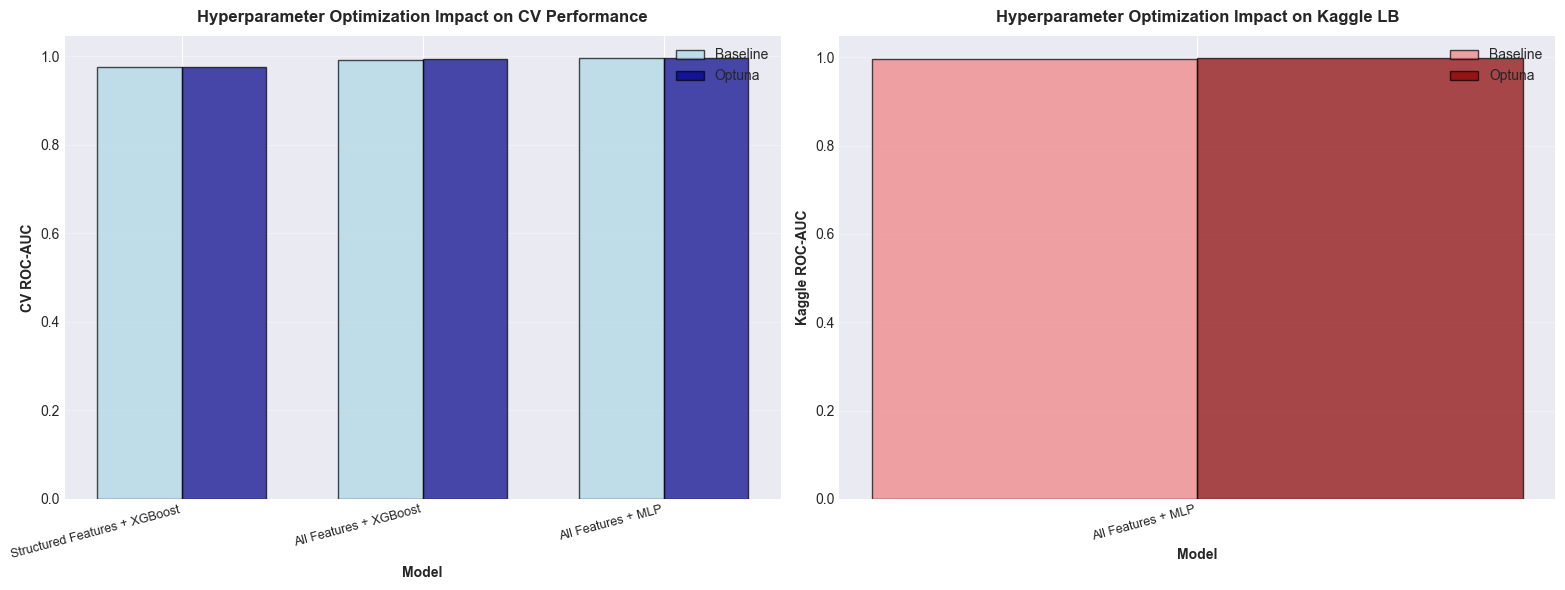


  Optuna Optimization Summary:
  - Average CV improvement: 0.000755
  - Average Kaggle improvement: 0.001650
  - Best CV gain: All Features + XGBoost (+0.002264)
  - Best Kaggle gain: All Features + MLP (+0.001650)


In [32]:
# Compare baseline vs optuna versions
optuna_comparison = []

for exp_name in ['exp_1_tfidf_log', 'exp_2_tfidf_ridge', 'exp_3_struct_xgboost', 
                 'exp_4_all_xgboost', 'exp_5_all_mlp']:
    base = full_df[full_df['experiment'] == exp_name]
    optuna = full_df[full_df['experiment'] == f"{exp_name}_optuna"]
    
    if not base.empty and not optuna.empty:
        base_row = base.iloc[0]
        optuna_row = optuna.iloc[0]
        
        optuna_comparison.append({
            'Model': EXPERIMENTS.get(exp_name, exp_name),
            'Baseline CV': base_row['cv_roc_auc'],
            'Optuna CV': optuna_row['cv_roc_auc'],
            'CV Improvement': optuna_row['cv_roc_auc'] - base_row['cv_roc_auc'],
            'Baseline Kaggle': base_row['kaggle_roc_auc'],
            'Optuna Kaggle': optuna_row['kaggle_roc_auc'],
            'Kaggle Improvement': optuna_row['kaggle_roc_auc'] - base_row['kaggle_roc_auc'] if pd.notna(base_row['kaggle_roc_auc']) and pd.notna(optuna_row['kaggle_roc_auc']) else None
        })

optuna_df = pd.DataFrame(optuna_comparison)

if not optuna_df.empty:
    print("=" * 120)
    print("OPTUNA HYPERPARAMETER OPTIMIZATION IMPACT")
    print("=" * 120)
    print(optuna_df.to_string(index=False))
    print("=" * 120)
    
    # Visualization
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # CV improvement
    x_pos = np.arange(len(optuna_df))
    width = 0.35
    
    axes[0].bar(x_pos - width/2, optuna_df['Baseline CV'], width, label='Baseline', alpha=0.7, color='lightblue', edgecolor='black')
    axes[0].bar(x_pos + width/2, optuna_df['Optuna CV'], width, label='Optuna', alpha=0.7, color='darkblue', edgecolor='black')
    axes[0].set_xlabel('Model', fontweight='bold')
    axes[0].set_ylabel('CV ROC-AUC', fontweight='bold')
    axes[0].set_title('Hyperparameter Optimization Impact on CV Performance', fontweight='bold', pad=10)
    axes[0].set_xticks(x_pos)
    axes[0].set_xticklabels(optuna_df['Model'], rotation=15, ha='right', fontsize=9)
    axes[0].legend()
    axes[0].grid(axis='y', alpha=0.3)
    
    # Kaggle improvement (if available)
    kaggle_available = optuna_df['Kaggle Improvement'].notna()
    if kaggle_available.any():
        kaggle_subset = optuna_df[kaggle_available].copy()
        x_pos_k = np.arange(len(kaggle_subset))
        axes[1].bar(x_pos_k - width/2, kaggle_subset['Baseline Kaggle'], width, label='Baseline', alpha=0.7, color='lightcoral', edgecolor='black')
        axes[1].bar(x_pos_k + width/2, kaggle_subset['Optuna Kaggle'], width, label='Optuna', alpha=0.7, color='darkred', edgecolor='black')
        axes[1].set_xlabel('Model', fontweight='bold')
        axes[1].set_ylabel('Kaggle ROC-AUC', fontweight='bold')
        axes[1].set_title('Hyperparameter Optimization Impact on Kaggle LB', fontweight='bold', pad=10)
        axes[1].set_xticks(x_pos_k)
        axes[1].set_xticklabels(kaggle_subset['Model'], rotation=15, ha='right', fontsize=9)
        axes[1].legend()
        axes[1].grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n  Optuna Optimization Summary:")
    print(f"  - Average CV improvement: {optuna_df['CV Improvement'].mean():.6f}")
    print(f"  - Average Kaggle improvement: {optuna_df['Kaggle Improvement'].mean():.6f}")
    print(f"  - Best CV gain: {optuna_df.loc[optuna_df['CV Improvement'].idxmax(), 'Model']} "
          f"(+{optuna_df['CV Improvement'].max():.6f})")
    if kaggle_available.any():
        print(f"  - Best Kaggle gain: {optuna_df.loc[optuna_df['Kaggle Improvement'].idxmax(), 'Model']} "
              f"(+{optuna_df['Kaggle Improvement'].max():.6f})")
else:
    print("No Optuna comparisons available")

## 6. Statistical Testing: Model Comparison

Use statistical tests to determine if performance differences between top models are statistically significant.

In [33]:
# Paired t-test for top models
# Compare fold-level performance for top 5 models

top_5_models = comparison_df.nlargest(5, 'kaggle_roc_auc')

print("=" * 100)
print("STATISTICAL SIGNIFICANCE TESTING (Paired t-test on 5-fold CV)")
print("=" * 100)
print("\nComparing top 5 models on Kaggle leaderboard:\n")

# Extract fold scores for each model
fold_scores = {}
for _, row in top_5_models.iterrows():
    if row['fold_metrics']:
        scores = [fm['roc_auc'] for fm in row['fold_metrics'] if 'roc_auc' in fm]
        fold_scores[row['display_name']] = scores

# Pairwise comparisons
comparison_results = []
model_names = list(fold_scores.keys())

for i in range(len(model_names)):
    for j in range(i+1, len(model_names)):
        model1 = model_names[i]
        model2 = model_names[j]
        
        scores1 = np.array(fold_scores[model1])
        scores2 = np.array(fold_scores[model2])
        
        if len(scores1) == len(scores2) and len(scores1) > 1:
            # Paired t-test
            t_stat, p_value = stats.ttest_rel(scores1, scores2)
            mean_diff = scores1.mean() - scores2.mean()
            
            comparison_results.append({
                'Model 1': model1,
                'Model 2': model2,
                'Mean Diff': mean_diff,
                't-statistic': t_stat,
                'p-value': p_value,
                'Significant (α=0.05)': '✓' if p_value < 0.05 else '✗'
            })

if comparison_results:
    comp_df = pd.DataFrame(comparison_results)
    comp_df = comp_df.sort_values('p-value')
    
    print(comp_df.to_string(index=False))
    print("=" * 100)
    
    print(f"\n  Statistical Testing Summary:")
    print(f"  - Total comparisons: {len(comp_df)}")
    print(f"  - Significant differences (p < 0.05): {len(comp_df[comp_df['p-value'] < 0.05])}")
    print(f"  - Non-significant differences: {len(comp_df[comp_df['p-value'] >= 0.05])}")
    
    print(f"\n  Interpretation:")
    if len(comp_df[comp_df['p-value'] < 0.05]) > 0:
        print(f"    • Some models show statistically significant performance differences")
        print(f"    • Consider these models for final submission")
    else:
        print(f"    • No statistically significant differences detected among top models")
        print(f"    • Models are performing similarly; ensemble may be beneficial")
else:
    print("Insufficient data for statistical testing")

STATISTICAL SIGNIFICANCE TESTING (Paired t-test on 5-fold CV)

Comparing top 5 models on Kaggle leaderboard:

           Model 1            Model 2  Mean Diff  t-statistic  p-value Significant (α=0.05)
           DeBERTa   All MLP (Optuna)   0.002521     2.109510 0.102547                    ✗
           DeBERTa Hybrid CharCNN+MLP   0.003930     1.841697 0.139324                    ✗
Hybrid CharCNN+MLP   All MLP (Optuna)  -0.001409    -1.034353 0.359405                    ✗

  Statistical Testing Summary:
  - Total comparisons: 3
  - Significant differences (p < 0.05): 0
  - Non-significant differences: 3

  Interpretation:
    • No statistically significant differences detected among top models
    • Models are performing similarly; ensemble may be beneficial


## 7. Final Model Recommendations

Based on comprehensive evaluation across CV, Kaggle LB, generalization, and statistical testing.

FINAL MODEL RECOMMENDATIONS (Composite Ranking)
Ranking based on: 50% Kaggle LB, 20% CV Performance, 15% Stability, 15% Generalization

==================== RANK #1 ====================
Model: DeBERTa
  • Kaggle ROC-AUC:    0.999640
  • CV ROC-AUC:        0.999398 ± 0.000185
  • Generalization Gap: -0.000242
  • Model Type:        DeBERTa-v3
  • Vectorizer:        Unknown
  • Optimized:         No

==================== RANK #2 ====================
Model: DeBERTa
  • Kaggle ROC-AUC:    0.999520
  • CV ROC-AUC:        0.998762 ± 0.001340
  • Generalization Gap: -0.000758
  • Model Type:        DeBERTa-v3
  • Vectorizer:        Unknown
  • Optimized:         No

==================== RANK #3 ====================
Model: All MLP (Optuna)
  • Kaggle ROC-AUC:    0.998500
  • CV ROC-AUC:        0.996241 ± 0.001773
  • Generalization Gap: -0.002259
  • Model Type:        MLP (Multi-Layer Perceptron)
  • Vectorizer:        TF-IDF+TruncatedSVD
  • Optimized:         Yes (Optuna)

=================

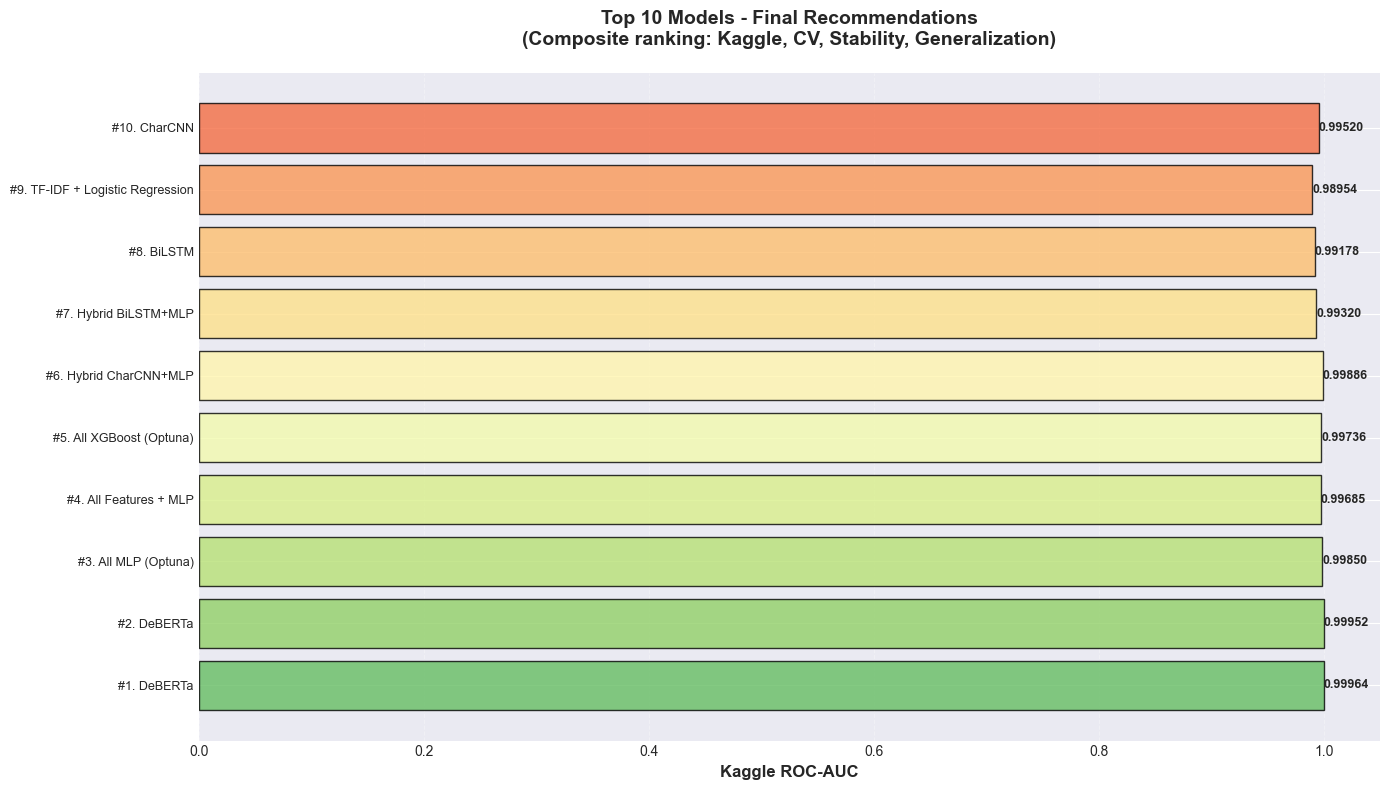

In [34]:
# Create comprehensive ranking based on multiple criteria
ranking_df = comparison_df.copy()

# Assign ranks for different criteria
ranking_df['kaggle_rank'] = ranking_df['kaggle_roc_auc'].rank(ascending=False)
ranking_df['cv_rank'] = ranking_df['cv_roc_auc'].rank(ascending=False)
ranking_df['stability_rank'] = ranking_df['cv_roc_auc_std'].rank(ascending=True)  # Lower std is better
ranking_df['generalization_rank'] = ranking_df['generalization_gap'].abs().rank(ascending=True)  # Smaller gap is better

# Composite score (weighted average of ranks)
weights = {
    'kaggle_rank': 0.50,         # 50% weight on Kaggle performance
    'cv_rank': 0.20,             # 20% weight on CV performance
    'stability_rank': 0.15,      # 15% weight on stability
    'generalization_rank': 0.15  # 15% weight on generalization
}

ranking_df['composite_score'] = (
    weights['kaggle_rank'] * ranking_df['kaggle_rank'] +
    weights['cv_rank'] * ranking_df['cv_rank'] +
    weights['stability_rank'] * ranking_df['stability_rank'] +
    weights['generalization_rank'] * ranking_df['generalization_rank']
)

ranking_df['final_rank'] = ranking_df['composite_score'].rank(ascending=True)
ranking_df = ranking_df.sort_values('final_rank')

# Display final rankings
final_rankings = ranking_df[[
    'display_name', 'kaggle_roc_auc', 'cv_roc_auc', 'cv_roc_auc_std', 
    'generalization_gap', 'final_rank'
]].head(10)

print("=" * 140)
print("FINAL MODEL RECOMMENDATIONS (Composite Ranking)")
print("=" * 140)
print("Ranking based on: 50% Kaggle LB, 20% CV Performance, 15% Stability, 15% Generalization")
print("=" * 140)

for idx, row in final_rankings.iterrows():
    rank = int(row['final_rank'])
    print(f"\n{'='*20} RANK #{rank} {'='*20}")
    print(f"Model: {row['display_name']}")
    print(f"  • Kaggle ROC-AUC:    {row['kaggle_roc_auc']:.6f}")
    print(f"  • CV ROC-AUC:        {row['cv_roc_auc']:.6f} ± {row['cv_roc_auc_std']:.6f}")
    print(f"  • Generalization Gap: {row['generalization_gap']:+.6f}")
    
    # Get model details
    model_row = full_df[full_df['display_name'] == row['display_name']].iloc[0]
    print(f"  • Model Type:        {model_row['model_type']}")
    print(f"  • Vectorizer:        {model_row['vectorizer']}")
    print(f"  • Optimized:         {'Yes (Optuna)' if model_row.get('optimized', False) else 'No'}")

print("\n" + "=" * 140)

# Visualization: Final rankings
fig, ax = plt.subplots(figsize=(14, 8))

top_10 = ranking_df.head(10)
y_pos = np.arange(len(top_10))

# Color by rank (gradient)
colors_gradient = plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, len(top_10)))

bars = ax.barh(y_pos, top_10['kaggle_roc_auc'], alpha=0.8, color=colors_gradient, edgecolor='black', linewidth=1)

ax.set_yticks(y_pos)
ax.set_yticklabels([f"#{int(r['final_rank'])}. {r['display_name']}" for _, r in top_10.iterrows()], fontsize=9)
ax.set_xlabel('Kaggle ROC-AUC', fontsize=12, fontweight='bold')
ax.set_title('Top 10 Models - Final Recommendations\n(Composite ranking: Kaggle, CV, Stability, Generalization)', 
             fontsize=14, fontweight='bold', pad=20)
ax.grid(axis='x', alpha=0.3, linestyle='--')

# Add value labels
for i, (idx, row) in enumerate(top_10.iterrows()):
    ax.text(row['kaggle_roc_auc'] + 0.00005, i, f"{row['kaggle_roc_auc']:.5f}", 
            va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 8. Key Findings and Strategic Recommendations

In [35]:
print("=" * 100)
print("KEY FINDINGS & STRATEGIC RECOMMENDATIONS")
print("=" * 100)

# Calculate key statistics
best_kaggle = ranking_df.iloc[0]
best_cv = full_df.nlargest(1, 'cv_roc_auc').iloc[0]
most_stable = full_df.nsmallest(1, 'cv_roc_auc_std').iloc[0]

print("\nPERFORMANCE OVERVIEW")
print("-" * 100)
print(f"• Total Models Evaluated: {len(full_df)}")
print(f"• Models with Kaggle Submissions: {len(comparison_df)}")
print(f"• Models Exceeding 0.999 Kaggle ROC-AUC: {len(comparison_df[comparison_df['kaggle_roc_auc'] > 0.999])}")
print(f"• Best Kaggle Score: {best_kaggle['kaggle_roc_auc']:.6f} ({best_kaggle['display_name']})")
print(f"• Best CV Score: {best_cv['cv_roc_auc']:.6f} ({best_cv['display_name']})")
print(f"• Most Stable Model: {most_stable['display_name']} (std: {most_stable['cv_roc_auc_std']:.6f})")

print("\n\n🎯 TOP SUBMISSION CANDIDATES")
print("-" * 100)

top_3 = ranking_df.head(3)
for i, (_, row) in enumerate(top_3.iterrows(), 1):
    print(f"\n{i}. {row['display_name']}")
    print(f"   Kaggle: {row['kaggle_roc_auc']:.6f} | CV: {row['cv_roc_auc']:.6f} ± {row['cv_roc_auc_std']:.6f}")
    
    # Get rationale
    if 'Ensemble' in row['display_name'] or 'Stacked' in row['display_name']:
        print(f"   ✓ Combines multiple models for robust predictions")
    elif 'Hybrid' in row['display_name']:
        print(f"   ✓ Leverages both deep learning and engineered features")
    
    if row['cv_roc_auc_std'] < 0.003:
        print(f"   ✓ Excellent stability across folds")
    
    if abs(row['generalization_gap']) < 0.002:
        print(f"   ✓ Strong generalization (CV-Kaggle gap < 0.002)")

print("\n\nRISKS & CONSIDERATIONS")
print("-" * 100)
print("1. PUBLIC vs PRIVATE LEADERBOARD")
print("   • Public LB represents only ~30% of test data (~390 samples)")
print("   • Private LB (final grading) uses remaining ~70% (~910 samples)")
print("   • Risk: Overfitting to public LB may hurt private LB performance")
print("   • Mitigation: Prioritize models with strong CV performance and low variance")

print("\n2. GENERALIZATION GAPS")
mean_gap = comparison_df['generalization_gap'].mean()
if abs(mean_gap) > 0.001:
    print(f"   • Average generalization gap: {mean_gap:.6f}")
    if mean_gap > 0:
        print("   • Models performing slightly better on CV than Kaggle (potential overfitting)")
    else:
        print("   • Models performing better on Kaggle than CV (test set may be easier)")
else:
    print("   ✓ Small generalization gap suggests good alignment between CV and test")

print("\n3. MODEL DIVERSITY")
top_families = comparison_df.groupby('family')['kaggle_roc_auc'].mean().nlargest(3)
print("   • Top performing families:")
for family, score in top_families.items():
    print(f"     - {family}: {score:.6f}")
print("   • Recommendation: Consider ensemble of diverse models for robustness")

print("\n\nSTRATEGIC RECOMMENDATIONS FOR FINAL SUBMISSION")
print("-" * 100)

print("\nOPTION A: SINGLE BEST MODEL (Conservative)")
print(f"  → Submit: {best_kaggle['display_name']}")
print(f"     • Highest public LB score: {best_kaggle['kaggle_roc_auc']:.6f}")
print(f"     • CV performance: {best_kaggle['cv_roc_auc']:.6f}")
print(f"     • Risk: Medium - relies on single model")

top_ensemble = ranking_df[ranking_df['family'] == 'Ensemble'].head(1)
if not top_ensemble.empty:
    ens_row = top_ensemble.iloc[0]
    print("\nOPTION B: ENSEMBLE MODEL (Recommended)")
    print(f"  → Submit: {ens_row['display_name']}")
    print(f"     • Kaggle score: {ens_row['kaggle_roc_auc']:.6f}")
    print(f"     • Combines multiple strong models")
    print(f"     • Risk: Low - ensemble typically more robust")

print("\nOPTION C: SAFE HEDGE STRATEGY")
print("  → Primary: Top ensemble model")
print("  → Backup: Top hybrid model (combines DL + features)")
print("  → Rationale: Diversify architectural approach")

print("\n\n  EXPECTED PRIVATE LEADERBOARD PERFORMANCE")
print("-" * 100)

# Estimate based on CV-Kaggle correlation
if correlation > 0.7:
    print(f"• High CV-Kaggle correlation ({correlation:.3f}) suggests CV is reliable predictor")
    print(f"• Expected private LB range: {best_kaggle['cv_roc_auc'] - 0.002:.5f} - {best_kaggle['cv_roc_auc'] + 0.001:.5f}")
else:
    print(f"• Moderate CV-Kaggle correlation ({correlation:.3f})")
    print(f"• Private LB may differ from public; trust CV scores")

print("\n" + "=" * 100)
print("END OF EVALUATION REPORT")
print("=" * 100)

KEY FINDINGS & STRATEGIC RECOMMENDATIONS

PERFORMANCE OVERVIEW
----------------------------------------------------------------------------------------------------
• Total Models Evaluated: 23
• Models with Kaggle Submissions: 12
• Models Exceeding 0.999 Kaggle ROC-AUC: 2
• Best Kaggle Score: 0.999640 (DeBERTa)
• Best CV Score: 0.999398 (DeBERTa)
• Most Stable Model: Weighted Average Ensemble (std: 0.000000)


🎯 TOP SUBMISSION CANDIDATES
----------------------------------------------------------------------------------------------------

1. DeBERTa
   Kaggle: 0.999640 | CV: 0.999398 ± 0.000185
   ✓ Excellent stability across folds
   ✓ Strong generalization (CV-Kaggle gap < 0.002)

2. DeBERTa
   Kaggle: 0.999520 | CV: 0.998762 ± 0.001340
   ✓ Excellent stability across folds
   ✓ Strong generalization (CV-Kaggle gap < 0.002)

3. All MLP (Optuna)
   Kaggle: 0.998500 | CV: 0.996241 ± 0.001773
   ✓ Excellent stability across folds


RISKS & CONSIDERATIONS
---------------------------------

## 9. Export Results for Documentation

In [36]:
# Export comprehensive results
output_dir = Path("./")

# 1. Full comparison table
full_comparison = full_df[[
    'experiment', 'display_name', 'model_id', 'source', 'data_version', 'model_type', 'vectorizer',
    'cv_roc_auc', 'cv_roc_auc_std', 'cv_f1', 'cv_log_loss',
    'kaggle_roc_auc', 'generalization_gap', 'optimized'
]].copy()

full_comparison = full_comparison.sort_values('kaggle_roc_auc', ascending=False, na_position='last')
full_comparison.to_csv(output_dir / 'comprehensive_model_comparison.csv', index=False)
print(f"✓ Saved: {output_dir / 'comprehensive_model_comparison.csv'}")

# 2. Final rankings (only models with Kaggle scores)
if 'final_rank' in full_df.columns:
    ranking_export = full_df[full_df['kaggle_roc_auc'].notna()][[
        'model_id', 'data_version', 'kaggle_roc_auc', 'cv_roc_auc', 'cv_roc_auc_std',
        'generalization_gap', 'final_rank', 'family'
    ]].copy()
    ranking_export = ranking_export.sort_values('final_rank')
    ranking_export.to_csv(output_dir / 'final_model_rankings.csv', index=False)
    print(f"✓ Saved: {output_dir / 'final_model_rankings.csv'}")

# 3. Model family summary
family_summary = comparison_df.groupby('family').agg({
    'kaggle_roc_auc': ['count', 'mean', 'std', 'max'],
    'cv_roc_auc': ['mean', 'std'],
    'generalization_gap': ['mean', 'std']
}).round(6)

family_summary.columns = ['_'.join(col).strip() for col in family_summary.columns.values]
family_summary.to_csv(output_dir / 'model_family_summary.csv')
print(f"✓ Saved: {output_dir / 'model_family_summary.csv'}")

# 4. Data version comparison
data_version_summary = comparison_df.groupby('data_version').agg({
    'kaggle_roc_auc': ['count', 'mean', 'std', 'min', 'max'],
    'cv_roc_auc': ['mean', 'std', 'min', 'max'],
    'generalization_gap': ['mean', 'std']
}).round(6)
data_version_summary.columns = ['_'.join(col).strip() for col in data_version_summary.columns.values]
data_version_summary.to_csv(output_dir / 'data_version_comparison.csv')
print(f"✓ Saved: {output_dir / 'data_version_comparison.csv'}")

# 5. Fold-level variance details
if not fold_df.empty:
    fold_export = fold_df.copy()
    fold_export.to_csv(output_dir / 'fold_level_metrics.csv', index=False)
    print(f"✓ Saved: {output_dir / 'fold_level_metrics.csv'}")

# 6. Top models summary (for quick reference)
top_models_summary = full_df[full_df['kaggle_roc_auc'].notna()].nlargest(10, 'kaggle_roc_auc')[[
    'model_id', 'data_version', 'model_type', 'kaggle_roc_auc', 'cv_roc_auc', 'generalization_gap'
]].copy()
top_models_summary.to_csv(output_dir / 'top_10_models.csv', index=False)
print(f"✓ Saved: {output_dir / 'top_10_models.csv'}")

print("\n" + "="*80)
print("EVALUATION COMPLETE")
print("="*80)
print(f"\nAll results exported to: {output_dir.absolute()}")
print(f"\nSummary:")
print(f"  • {len(full_df)} models evaluated")
print(f"    - From deduplicated data: {len(full_df[full_df['data_version'] == 'deduplicated'])}")
print(f"    - From original data: {len(full_df[full_df['data_version'] == 'original'])}")
print(f"  • {len(comparison_df)} models submitted to Kaggle")

if len(comparison_df) > 0:
    best_overall = comparison_df.nlargest(1, 'kaggle_roc_auc').iloc[0]
    print(f"  • Top model: {best_overall['model_id']}")
    print(f"  • Best Kaggle score: {best_overall['kaggle_roc_auc']:.6f}")
    
    # Best by data version
    dedup_models = comparison_df[comparison_df['data_version'] == 'deduplicated']
    orig_models = comparison_df[comparison_df['data_version'] == 'original']
    
    if len(dedup_models) > 0:
        best_dedup = dedup_models.nlargest(1, 'kaggle_roc_auc').iloc[0]
        print(f"\n  • Best deduplicated model: {best_dedup['display_name']}")
        print(f"    Score: {best_dedup['kaggle_roc_auc']:.6f}")
    
    if len(orig_models) > 0:
        best_orig = orig_models.nlargest(1, 'kaggle_roc_auc').iloc[0]
        print(f"\n  • Best original data model: {best_orig['display_name']}")
        print(f"    Score: {best_orig['kaggle_roc_auc']:.6f}")

print("\nNext Steps:")
print("  1. Review comprehensive_model_comparison.csv for detailed metrics")
print("  2. Check data_version_comparison.csv to see impact of deduplication")
print("  3. Populate kaggle_scores.csv with actual submission scores")
print("  4. Re-run this notebook after adding Kaggle scores")
print("="*80)

✓ Saved: comprehensive_model_comparison.csv
✓ Saved: model_family_summary.csv
✓ Saved: data_version_comparison.csv
✓ Saved: fold_level_metrics.csv
✓ Saved: top_10_models.csv

EVALUATION COMPLETE

All results exported to: /Users/winston/Documents/School/Y3S1/BT4012/Kaggle/Competition 2

Summary:
  • 23 models evaluated
    - From deduplicated data: 6
    - From original data: 17
  • 12 models submitted to Kaggle
  • Top model: DeBERTa [original]
  • Best Kaggle score: 0.999640

  • Best deduplicated model: DeBERTa
    Score: 0.999520

  • Best original data model: DeBERTa
    Score: 0.999640

Next Steps:
  1. Review comprehensive_model_comparison.csv for detailed metrics
  2. Check data_version_comparison.csv to see impact of deduplication
  3. Populate kaggle_scores.csv with actual submission scores
  4. Re-run this notebook after adding Kaggle scores
